# Proyecto: STATS19 #

Proyecto para el Módulo 1 del Diplomado de Métodos Estadísticos y Matemáticos para la Ciencia de Datos, Ed. 3 (Facultad de Ciencias, UNAM).

**Integrantes del equipo:**
- Guillermo Adolfo Méndez Roche
- Sofía Quetzalli González Robles
- [Nombre completo integrante 3]
- [Nombre completo integrante 4]
- [Nombre completo integrante 5]

**Fecha:** 22 de noviembre de 2026

## 1. Introducción ##

### 1.1. Fuente de los datos ###

El presente proyecto utiliza la base de datos **STATS19**, que recopila información oficial sobre siniestros viales ocurridos en Gran Bretaña. Los datos son reportados por 44 fuerzas policiales de Escocia, Gales e Inglaterra. Cabe mencionar que únicamente se registran siniestros que cumplen las siguientes tres condiciones:

1. Haber sucedido en la vía pública.

2. Haber causado lesiones o el fallecimiento de al menos una persona.

3. Haber llegado a conocimiento de la policía en un plazo máximo de 30 días después del siniestro.

**Procedencia y condiciones de uso.** La base de datos es publicada abiertamente por el Departamento de Transporte del Reino Unido (*DfT* por sus siglas en inglés) bajo la licencia **Open Government Licence v3.0 (OGL)**, la cual permite copiar, publicar, distribuir, adaptar y analizar la información libremente con fines académicos o analíticos, siempre que se cite la fuente oficial.

La documentación completa de los datos puede consultarse en [este enlace](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data).

> **Advertencia.** El Departamento de Transporte del Reino Unido advierte que en STATS19 existe un subregistro importante de personas que sufren lesiones no mortales en siniestros viales, particularmente cuando se trata de lesiones leves. En particular, la ausencia de un registro de lesión no implica necesariamente que la persona haya resultado ilesa.

### 1.2. Datos de STATS19 ###

Como se mencionó anteriormente, STATS19 actualiza sus datos anualmente. No obstante, para el alcance de este proyecto, trabajaremos con los datos correspondientes a los años 2023, 2024 y 2025.

Para cada año, los datos se distribuyen en tres tablas:

- `collisions`: Cada fila representa un siniestro reportado. Contiene, entre otras variables, la fecha y hora del siniestro, así como el número de vehículos involucrados.

- `vehicles`: Cada fila representa un vehículo involucrado en un siniestro. Contiene variables como el tipo de vehículo, el sexo de quien conducía la unidad y el primer punto de impacto.

- `casualties`: Cada fila representa una persona lesionada o fallecida registrada como consecuencia de un siniestro. Contiene la clase de víctima (conductor, pasajero o peatón), la gravedad de sus lesiones y, cuando corresponde, la referencia del vehículo asociado.

#### 1.2.1. Guías y documentación ####

Algunas de las variables categóricas en STATS19 funcionan mediante códigos. Para interpretar dichos códigos, el Departamento de Transporte del Reino Unido proporciona una **guía oficial de decodificación de variables**, donde se desglosan los códigos asociados con ciertas variables y sus significados. 

La guía vigente al momento de la realización de este proyecto se encuentra en la carpeta [insertar carpeta] del repositorio. Adicionalmente, se incluyen las instrucciones oficiales vigentes de STATS20, que explican los criterios utilizados por las fuerzas policiales para registrar la información.

### 1.3. Identificadores y relaciones entre tablas ###

Para mantener un control de cuáles vehículos y víctimas pertenecen a cada siniestro, STATS19 implementa el uso de tres tipos de identificadores:

- En `collisions`, cada siniestro se identifica mediante un `collision_index`, que es una referencia alfanumérica única para cada siniestro.

- En `vehicles`, cada vehículo se identifica mediante la combinación de un `collision_index` y un `vehicle_reference`, que toma un valor único para cada vehículo dentro de un siniestro.

- En `casualties`, cada víctima se identifica mediante la combinación de `collision_index` y un `casualty_reference` (de manera análoga a como funcionan `collision_index` y `vehicle_reference` en el caso anterior).

  Cabe mencionar que en `casualties` también aparece la columna `vehicle_reference`, que permite vincular a las víctimas con un vehículo del siniestro, cuando corresponde.

Estos identificadores nos permitirán cruzar información de los siniestros, los vehículos involucrados y las víctimas registradas.

---

*Ejemplo.* A continuación incluimos un ejemplo ilustrativo de la tabla `vehicles`. Las filas del mismo color corresponden a vehículos registrados en un mismo siniestro.

Nótese que los valores de la columna `vehicle_type` son números enteros, pero la variable es **cualitativa nominal**, pues dichos códigos representan categorías de vehículos. En los tres años analizados, el código correspondiente a los automóviles es `9`.

In [6]:
# @title
import pandas as pd

# Tabla ilustrativa: la tabla `vehicles` tiene dos filas (una por vehículo) por cada siniestro.
# Cada siniestro se resalta con un color distinto.
ejemplo = pd.DataFrame({
    "collision_index": ["2025010551786", "2025010551786", "2025010551795", "2025010551795", "2025010551794", "⋮"],
    "vehicle_reference": ["1", "2", "1", "2", "1", "⋮"],
    "vehicle_type": ["3", "9", "9", "1", "9", "⋮"],
    "⋯": ["⋯", "⋯", "⋯", "⋯", "⋯", "⋱"]
})
color_siniestro = {
    "2025010551786": "#FFE699",
    "2025010551795": "#DCEAF5",
    "2025010551794": "#FFE9D6",
    "⋮": "#FFFFFF"
}

def colorear_por_siniestro(fila):
    return [f"background-color: {color_siniestro[fila['collision_index']]}"] * len(fila)

ejemplo.style.hide(axis="index").apply(colorear_por_siniestro, axis=1).set_table_styles([
    {"selector": "", "props": [("margin", "auto"), ("border-collapse", "collapse"), ("color", "#22232F")]},
    {"selector": "th", "props": [("background-color", "#FFFFFF"), ("text-align", "center"),
                                 ("padding", "6px 12px"), ("border-bottom", "1px solid #CCCCCC")]},
    {"selector": "td", "props": [("text-align", "center"), ("padding", "4px 12px")]}
])

collision_index,vehicle_reference,vehicle_type,⋯
2025010551786,1,3,⋯
2025010551786,2,9,⋯
2025010551795,1,9,⋯
2025010551795,2,1,⋯
2025010551794,1,9,⋯
⋮,⋮,⋮,⋱


### 1.4. Planteamiento del problema ###

#### 1.4.1. Preguntas conductoras ####

El análisis que realizamos en este proyecto parte de la siguiente idea:

> En siniestros con exactamente dos automóviles y conductores de distinto sexo, ¿cómo se comparan la presencia y la gravedad de las lesiones registradas de ambos conductores?

Más concretamente, responderemos las siguientes preguntas de investigación de carácter descriptivo, aunque con ciertas acotaciones que mencionaremos enseguida:

> *Primera pregunta.* Si solo uno de los conductores presenta lesiones registradas, ¿existe una tendencia consistente sobre si se trata del conductor o de la conductora?

> *Segunda pregunta.* Si tanto el conductor como la conductora presentan lesiones registradas de distinta gravedad, ¿existe una tendencia sobre cuál de los dos presenta las lesiones más graves?

#### 1.4.2. Algunas consideraciones metodológicas ####

1. *Sobre las condiciones del siniestro.*

   Es importante considerar que tanto la presencia como la gravedad de las lesiones podrían estar influenciadas por las condiciones físicas de cada colisión. Puesto que STATS19 no reporta variables como la masa de los vehículos o la velocidad al momento del impacto, restringiremos nuestro análisis a siniestros en los que ambos automóviles registraron un **primer punto de impacto frontal** (`first_point_of_impact == 1`). 
   
   Sin embargo, es importante aclarar que esto no significa que los automóviles hayan chocado entre sí: por ejemplo, podría suceder que ambos automóviles hayan esquivado algún objeto en la vía y a causa de ello se hayan estrellado, cada uno por separado, con algún muro. Asimismo, esta restricción no garantiza que ambos automóviles hayan experimentado impactos de magnitud similar, de modo que no representa el control total de las condiciones físicas del siniestro.

2. *Sobre la clasificación entre la gravedad de las lesiones.*

   En la tabla `casualties`, donde cada registro se corresponde con una víctima, la columna `casualty_severity` es una variable categórica ordinal que describe el grado de gravedad de las lesiones de la víctima en una escala de tres severidades: mortal, grave y leve, codificadas como `1`, `2` y `3`, respectivamente.

   Respecto a dicha variable, el Departamento de Transporte del Reino Unido declara que existen diferencias en la distinción de lesiones leves y graves entre fuerzas policiales. En este sentido, analizar el comportamiento de dicha variable en áreas que abarquen distintas zonas policiales requiere de consideraciones adicionales contempladas en la documentación de STATS19.

   Para nuestra segunda pregunta conductora, comparamos la gravedad de las lesiones de dos conductores involucrados en un mismo siniestro. Esta comparación reduce la influencia de las diferencias de criterios entre fuerzas policiales, aunque no elimina posibles errores o inconsistencias en la clasificación de las lesiones dentro del mismo siniestro.

## 2. Carga y exploración inicial de datos ##

### 2.1. Importación de paquetes y carga de datos ###

El siguiente bloque de código importa los paquetes que utilizaremos a lo largo de este proyecto:

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carpeta para exportar resultados y figuras del repositorio
os.makedirs("resultados", exist_ok=True)

Además de los paquetes, fijamos aquí el **estilo visual** del proyecto para que todas las gráficas y tablas compartan la misma identidad:

- **Paleta.** Cuatro colores con un papel fijo en todo el notebook: azul para los hombres, naranja rojizo (bermellón) para las mujeres, y dos grises para los desenlaces en los que ambos o ninguno de los conductores tiene lesiones registradas. El par azul–bermellón proviene de la paleta de Okabe e Ito, diseñada para distinguirse bien incluso con daltonismo.
- **Gráficas.** Usamos `seaborn` (que trabaja sobre `matplotlib`) con un tema común. Elegimos gráficas estáticas porque se ven igual en Jupyter, en Colab, en GitHub y al exportar a PDF o HTML.
- **Tablas.** Cualquier `DataFrame` que se muestre en el notebook usa el mismo estilo: encabezado azul, filas alternadas y sin el índice numérico cuando este no aporta información.

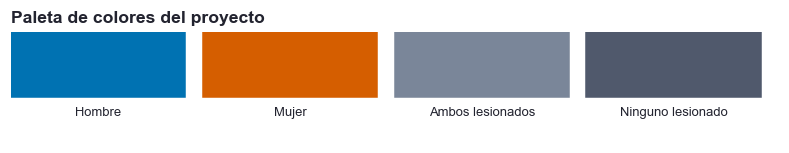

In [8]:
from IPython import get_ipython
from matplotlib.lines import Line2D
from pandas.io.formats.style import Styler

# Paleta de colores del proyecto
AZUL = "#0072B2"        # hombres
BERMELLÓN = "#D55E00"    # mujeres
GRIS_AZUL = "#7A8699"   # ambos conductores lesionados
GRIS = "#50596C"        # ningún conductor lesionado
TEXTO = "#22232F"
REJILLA = "#E3E7EE"
COLORES_SEXO = {"Hombre": AZUL, "Mujer": BERMELLÓN}

# Tamaños comunes de figura (pulgadas): una gráfica o dos paneles lado a lado
TAMAÑO_FIGURA = (9, 5)
TAMAÑO_FIGURA_DOBLE = (12, 5)
COLORES_DESENLACE = {
    "Solo hombre lesionado": AZUL,
    "Solo mujer lesionada": BERMELLÓN,
    "Ambos lesionados": GRIS_AZUL,
    "Ningún conductor lesionado": GRIS
}

# Tema de seaborn y matplotlib
sns.set_theme(
    style="whitegrid",
    context="notebook",
    font_scale=0.95,
    rc={
        "axes.edgecolor": REJILLA,
        "axes.labelcolor": TEXTO,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlelocation": "left",
        "axes.titleweight": "bold",
        "axes.titlesize": 11.5,
        "axes.labelsize": 10.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "legend.fontsize": 9.5,
        "figure.figsize": TAMAÑO_FIGURA,
        "grid.color": REJILLA,
        "grid.linewidth": 0.8,
        "text.color": TEXTO,
        "xtick.color": TEXTO,
        "ytick.color": TEXTO,
        "legend.frameon": False,
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "savefig.bbox": "tight"
    }
)

# Funciones auxiliares para las gráficas
def referencia(ax, valor=50, eje="y", etiqueta="Referencia: 50 %"):
    """Dibuja una línea punteada de referencia (por defecto, 50 %) que aparece en la leyenda."""
    linea = ax.axhline if eje == "y" else ax.axvline
    linea(valor, color="#666666", linestyle="--", linewidth=1.2, zorder=0, label=etiqueta)

def formato_pct(valor):
    """Porcentaje con un decimal y un espacio antes del símbolo (por ejemplo, 72.2 %)."""
    return f"{valor:.1f} %"

def ic_wilson(k, n, z=1.96):
    """Intervalo de confianza de Wilson (95 %) para k casos de n, expresado en porcentaje."""
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return 100 * (centro - mitad), 100 * (centro + mitad)

def barras_por_sexo(ax, etiquetas, k_hombre, k_mujer, n):
    """
    Barras agrupadas con el porcentaje de hombres y de mujeres en cada categoría (k / n),
    su intervalo de Wilson (95 %) y el valor escrito sobre cada barra.
    """
    etiquetas = list(etiquetas)
    k_hombre, k_mujer, n = (np.asarray(v, dtype=float) for v in (k_hombre, k_mujer, n))
    largo = pd.DataFrame({
        "Categoría": etiquetas * 2,
        "Persona": ["Hombre"] * len(etiquetas) + ["Mujer"] * len(etiquetas),
        "Porcentaje": np.concatenate([100 * k_hombre / n, 100 * k_mujer / n])
    })
    sns.barplot(data=largo, x="Categoría", y="Porcentaje", hue="Persona", order=etiquetas,
                hue_order=["Hombre", "Mujer"], palette=COLORES_SEXO, saturation=1, ax=ax)
    contenedores = list(ax.containers)
    for barras, k in zip(contenedores, (k_hombre, k_mujer)):
        inferior, superior = ic_wilson(k, n)
        porcentaje = 100 * k / n
        centros = [barra.get_x() + barra.get_width() / 2 for barra in barras]
        ax.errorbar(centros, porcentaje, yerr=[porcentaje - inferior, superior - porcentaje],
                    fmt="none", ecolor=TEXTO, capsize=3, linewidth=1.1)
        for centro, valor, límite in zip(centros, porcentaje, superior):
            ax.text(centro, límite + 1.5, formato_pct(valor), ha="center", va="bottom", fontsize=9,
                    bbox=dict(boxstyle="square,pad=0.12", facecolor="white", edgecolor="none", alpha=0.85))
    referencia(ax)
    ax.set_ylim(0, 100)

def caja_delta(ax, datos, columna, grupos):
    """
    Diagrama de cajas horizontal de una diferencia emparejada según el desenlace de lesiones.
    Marca la media con un rombo blanco y escribe el n de cada grupo; devuelve el símbolo de la media.
    """
    d = datos[datos["desenlace"].isin(grupos)].dropna(subset=[columna]).copy()
    n = d["desenlace"].value_counts()
    etiqueta = {g: f"{g}\n(n = {n[g]:,})" for g in grupos}
    d["grupo"] = d["desenlace"].map(etiqueta)
    orden = [etiqueta[g] for g in grupos]
    paleta = {etiqueta[g]: COLORES_DESENLACE[g] for g in grupos}
    sns.boxplot(data=d, x=columna, y="grupo", order=orden, hue="grupo", palette=paleta,
                width=0.55, linewidth=1.2, saturation=1, showfliers=False, legend=False, ax=ax,
                medianprops=dict(color="black", linewidth=2.0), showmeans=True,
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6))
    ax.grid(axis="y", visible=False)
    return Line2D([], [], marker="D", linestyle="", markerfacecolor="white",
                  markeredgecolor="black", markersize=6)

def leyenda_abajo(fig, ax, ncol=3, extra=None, otros_ejes=()):
    """Una sola leyenda centrada bajo la figura: entradas del eje más las de 'extra' [(símbolo, texto)]."""
    símbolos, textos = ax.get_legend_handles_labels()
    for símbolo, texto in reversed(extra or []):
        símbolos.insert(0, símbolo)
        textos.insert(0, texto)
    for eje in (ax, *otros_ejes):
        if eje.get_legend() is not None:
            eje.get_legend().remove()
    fig.legend(símbolos, textos, loc="lower center", ncol=ncol)

def titular(fig, título, subtítulo=None):
    """Título (con el mensaje principal) y subtítulo alineados a la izquierda, comunes a todas las figuras."""
    fig.suptitle(título, x=0.01, y=0.99, ha="left", va="top", fontsize=12.5, fontweight="bold")
    if subtítulo:
        fig.text(0.01, 0.935, subtítulo, ha="left", va="top", fontsize=9.5, color="#5B6070")

def guardar_figura(fig, nombre):
    """Guarda la figura en la carpeta resultados/ (PNG de alta resolución)."""
    os.makedirs("resultados", exist_ok=True)
    fig.savefig(f"resultados/{nombre}.png")

def cerrar_figura(fig, nombre, arriba=0.95):
    """Aplica los márgenes comunes, guarda el PNG en resultados/ y muestra la figura."""
    fig.tight_layout(rect=(0, 0.07, 1, arriba))
    guardar_figura(fig, nombre)
    plt.show()

# Estilo común de las tablas
ESTILO_TABLA = [
    {"selector": "", "props": [("border-collapse", "collapse"), ("font-size", "0.92em"), ("color", TEXTO)]},
    {"selector": "th", "props": [("background-color", AZUL), ("color", "white"), ("font-weight", "600"),
                                 ("padding", "6px 12px"), ("text-align", "center"), ("border", "none")]},
    {"selector": "td", "props": [("padding", "5px 12px"), ("text-align", "right"),
                                 ("background-color", "#FFFFFF"), ("color", TEXTO),
                                 ("border-bottom", f"1px solid {REJILLA}")]},
    {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", "#EEF0F4")]},
    {"selector": "tbody th", "props": [("background-color", "#EAF0F7"), ("color", TEXTO), ("text-align", "left")]}
]

def formato_número(valor):
    """Muestra los decimales estrictamente necesarios (máximo dos) y '–' en los datos faltantes."""
    if isinstance(valor, (float, np.floating)):
        if np.isnan(valor):
            return "–"
        return f"{valor:.2f}".rstrip("0").rstrip(".")
    return valor

def tabla_con_estilo(objeto):
    """Convierte un DataFrame (o un Styler) en una tabla HTML con el estilo del proyecto."""
    if isinstance(objeto, Styler):
        estilo = objeto
    else:
        estilo = objeto.style.format(formato_número, na_rep="–")
        if isinstance(objeto.index, pd.RangeIndex) and objeto.index.name is None:
            estilo = estilo.hide(axis="index")
        columnas_texto = objeto.select_dtypes(exclude="number").columns
        if len(columnas_texto) > 0:
            estilo = estilo.set_properties(subset=list(columnas_texto), **{"text-align": "left"})
    if not getattr(estilo, "_tema_aplicado", False):
        estilo.table_styles = ESTILO_TABLA + (estilo.table_styles or [])
        estilo._tema_aplicado = True
    return estilo.to_html()

pd.set_option("styler.render.max_rows", 60)
pd.set_option("styler.render.max_columns", 20)
_formateador_html = get_ipython().display_formatter.formatters["text/html"]
_formateador_html.for_type(pd.DataFrame, tabla_con_estilo)
_formateador_html.for_type(Styler, tabla_con_estilo)

# Vista previa de la paleta
fig, ax = plt.subplots(figsize=(TAMAÑO_FIGURA[0], 1.3))
colores_paleta = {"Hombre": AZUL, "Mujer": BERMELLÓN, "Ambos lesionados": GRIS_AZUL, "Ninguno lesionado": GRIS}
for posición, (nombre, color) in enumerate(colores_paleta.items()):
    ax.add_patch(plt.Rectangle((posición * 1.1, 0), 1, 1, color=color))
    ax.text(posición * 1.1 + 0.5, -0.15, nombre, ha="center", va="top", fontsize=8.5)
ax.set(xlim=(0, len(colores_paleta) * 1.1), ylim=(-0.7, 1))
ax.set_title("Paleta de colores del proyecto")
ax.axis("off")
plt.show()

Por otro lado, cargamos los datos de STATS19 para los años 2023, 2024 y 2025. Nótese que se cargan tres tablas por año: una tabla de siniestros, una de vehículos y una de víctimas para cada año, dando un total de nueve tablas.

In [9]:
# En su momento, estos datos se van a cargar desde una carpeta local (que el usuario descargará desde el repositiorio)
# Esta columna hay que modificarla cuando ya tengamos el repositorio y su estructura
# Datos de 2023
collisions_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2023.csv",
    low_memory=False
)
vehicles_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2023.csv",
    low_memory=False
)
casualties_2023 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2023.csv",
    low_memory=False
)

# Datos de 2024
collisions_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2024.csv",
    low_memory=False
)
vehicles_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2024.csv",
    low_memory=False
)
casualties_2024 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2024.csv",
    low_memory=False
)

# Datos de 2025
collisions_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-2025.csv",
    low_memory=False
)
vehicles_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-vehicle-2025.csv",
    low_memory=False
)
casualties_2025 = pd.read_csv(
    "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-casualty-2025.csv",
    low_memory=False
)
print("Datos de STATS19 cargados correctamente.")

Datos de STATS19 cargados correctamente.


Como estamos trabajando con datos de tres años distintos, es conveniente dejar clara la estructura que seguiremos. Dicha estructura estará dada en un diccionario:

In [10]:
# En este diccionario guardamos la información de STATS19 para cada año #
datos = {
    2023: {
        "collisions": collisions_2023,
        "vehicles": vehicles_2023,
        "casualties": casualties_2023
    },
    2024: {
        "collisions": collisions_2024,
        "vehicles": vehicles_2024,
        "casualties": casualties_2024
    },
    2025: {
        "collisions": collisions_2025,
        "vehicles": vehicles_2025,
        "casualties": casualties_2025
    }
}

Por ejemplo, si queremos visualizar las primeras tres filas de siniestros de 2025 podemos ejecutar el siguiente bloque de código:

In [11]:
datos[2025]["collisions"].head(3)

collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,number_of_casualties,date,day_of_week,time,local_authority_district,local_authority_ons_district,local_authority_highway,local_authority_highway_current,first_road_class,first_road_number,...
202517M101925,2025,17M101925,447673,519279,-1.26,54.57,17,3,1,1,04/02/2025,3,15:00,-1,E06000002,E06000002,E06000002,4,6541,...
202517L205225,2025,17L205225,454611,518597,-1.16,54.56,17,3,2,1,07/05/2025,4,09:35,-1,E06000003,E06000003,E06000003,5,0,...
2025070971700,2025,070971700,354476,382656,-2.69,53.34,7,3,2,2,27/11/2025,5,18:18,-1,E06000006,E06000006,E06000006,6,0,...


O bien, si queremos conocer el número de vehículos asociados con algún siniestro durante ese mismo año, podemos ejecutar la siguiente celda:

In [12]:
datos[2025]["vehicles"].shape[0]

183948

### 2.2. Exploración inicial de los datos ###

Comenzaremos por examinar las dimensiones de las nueve tablas originales, identificando el número de filas y columnas de cada una.

In [13]:
resumen = []

for año, tablas_anuales in datos.items():
    for título, tabla in tablas_anuales.items():
        resumen.append({
            "Año": año,
            "Tabla": título,
            "Filas": tabla.shape[0],
            "Columnas": tabla.shape[1]
        })

resumen = pd.DataFrame(resumen)

for año, grupo in resumen.groupby("Año"):
    print(f"Tablas del año {año}:")
    display(grupo[["Tabla", "Filas", "Columnas"]].reset_index(drop=True))

Tablas del año 2023:


Tabla,Filas,Columnas
collisions,104258,44
vehicles,189815,32
casualties,132977,24


Tablas del año 2024:


Tabla,Filas,Columnas
collisions,100927,44
vehicles,183514,32
casualties,128272,24


Tablas del año 2025:


Tabla,Filas,Columnas
collisions,101525,44
vehicles,183948,32
casualties,127883,24


### 2.3. Selección y verificación de variables ###

Comenzamos por identificar cada una de las variables que serán necesarias para realizar nuestro análisis.

In [14]:
# De la tabla de siniestros solo nos interesan:
# Su identificador
# El número de vehículos involucrados
variables_siniestros = ["collision_index",
                        "number_of_vehicles"
                        ]

# De la tabla de vehículos solo nos interesan:
# El identificador del siniestro al que corresponden
# El número de referencia dentro del siniestro
# El tipo de vehículo
# El sexo del conductor
# El primer punto de impacto
variables_vehículos = ["collision_index",
                       "vehicle_reference",
                       "vehicle_type",
                       "sex_of_driver",
                       "first_point_of_impact"
                       ]

# De la tabla de víctimas solo nos interesan:
# El identificador del siniestro al que corresponden
# El número de referencia de la víctima dentro del siniestro
# El número de referencia del vehículo asociado
# La clase de víctima
# La gravedad de las lesiones
variables_víctimas = ["collision_index",
                      "casualty_reference",
                      "vehicle_reference",
                      "casualty_class",
                      "casualty_severity"]

# Guardamos las variables que nos interesan en un diccionario
variables = {"siniestros": variables_siniestros,
             "vehículos": variables_vehículos,
             "víctimas": variables_víctimas
            }

#### 2.3.1. Presencia de las variables en los tres años ####

El siguiente paso será verificar que las variables de interés estén presentes en las tablas de los tres años a analizar (esto porque, en principio, la estructura de las tablas de STATS19 puede variar año con año).

El siguiente bloque de código define y ejecuta una función que toma un `int` (el año) como argumento y verifica que las variables de interés aparezcan en las tablas correspondientes a dicho año. En caso de no encontrar alguna, se obtiene un `AssertionError` y un mensaje con más información al respecto.

In [15]:
def verificar_variables(año: int) -> None:
    """Verifica que las variables de interés existan en las tablas del año indicado."""
    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]
    víctimas = datos[año]["casualties"]
    assert set(variables["siniestros"]).issubset(siniestros.columns), (
        f"Faltan columnas en collisions ({año})."
    )
    assert set(variables["vehículos"]).issubset(vehículos.columns), (
        f"Faltan columnas en vehicles ({año})."
    )
    assert set(variables["víctimas"]).issubset(víctimas.columns), (
        f"Faltan columnas en casualties ({año})."
    )

for año in datos.keys():
    verificar_variables(año)

print("Verificación exitosa: todas las variables seleccionadas existen en 2023, 2024 y 2025.")

Verificación exitosa: todas las variables seleccionadas existen en 2023, 2024 y 2025.


### 2.4. Calidad de los datos

Es importante considerar que, aun cuando todas las variables de interés estén presentes en los tres años, es posible que haya registros faltantes o datos erróneos en las columnas, lo cual podría afectar nuestro análisis.

#### 2.4.1. Identificadores repetidos ####

Recordemos que en la tabla `collisions` cada siniestro está identificado mediante un identificador `collision_index` (que, en principio, debe ser único).

A su vez, en la tabla `vehicles`, cada vehículo se identifica con una combinación de un `collision_index` (del siniestro al que corresponde) y una referencia del vehículo dentro de dicho siniestro (`vehicle_reference`).

Lo análogo sucede en la tabla de `casualties`, donde cada víctima está identificada por una combinación de un `collision_index` y una referencia de la víctima dentro del siniestro correspondiente (`casualty_reference`).

El siguiente bloque de código recorre cada uno de estos tipos de identificadores y verifica que no existan identificadores repetidos en cada una de las tablas, para cada año.

In [16]:
for año in datos.keys():
    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]
    víctimas = datos[año]["casualties"]
    print(f"Unicidad de identificadores para el año {año}\n")
    print(f"{'Identificadores de siniestros duplicados:':<45}{siniestros['collision_index'].duplicated().sum()}")
    print(f"{'Identificadores de vehículos duplicados:':<45}{vehículos.duplicated(['collision_index', 'vehicle_reference']).sum()}")
    print(f"{'Identificadores de víctimas duplicados:':<45}{víctimas.duplicated(['collision_index', 'casualty_reference']).sum()}\n")

Unicidad de identificadores para el año 2023

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0


Identificadores de víctimas duplicados:      0

Unicidad de identificadores para el año 2024

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0
Identificadores de víctimas duplicados:      0

Unicidad de identificadores para el año 2025

Identificadores de siniestros duplicados:    0
Identificadores de vehículos duplicados:     0
Identificadores de víctimas duplicados:      0



#### 2.4.2. Consistencia en el número de vehículos ####

Recordemos que, en la tabla `collisions`, la variable `number_of_vehicles` indica el número de vehículos involucrados en cada siniestro. Por su parte, la tabla `vehicles` contiene un registro por cada vehículo asociado a un siniestro, como se ilustró en la sección 1.3. En principio, debería suceder que:

$$ \text{no. de vehículos declarados para un siniestro} = \text{no. de filas de }\mathtt{vehicles}\text{ correspondientes a ese siniestro} $$

En ciertas partes del código usaremos el valor de `number_of_vehicles` para hacer operaciones con el número de vehículos involucrados en cierto siniestro, mientras que en otras será más fácil utilizar el número de filas en `vehicles`. Así pues, verificaremos que ambas cantidades coincidan para cada siniestro; solo posteriormente podremos utilizarlas indistintamente en nuestro análisis.

Para ello, agruparemos en `vehicles` según `collision_index` y contaremos el tamaño de cada grupo mediante el método `size`, lo cual arrojará el número de filas correspondientes: ese es el número que compararemos con `number_of_vehicles`.

In [17]:
resumen = []

for año in datos:
    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]

    # Número de vehículos registrados por cada siniestro
    número_de_filas = vehículos.groupby("collision_index").size()

    # Número de vehículos declarados en collisions
    número_declarado = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Comparamos ambas series
    discrepancias = número_de_filas.ne(número_declarado)
    resumen.append({"Año": año,
                    "Discrepancias": discrepancias.sum()})

display(pd.DataFrame(resumen).style.hide(axis="index"))

Año,Discrepancias
2023,0
2024,0
2025,0


#### 2.4.3. Calidad de las variables principales: sexo y gravedad de lesiones ####

Nuestras preguntas conductoras tienen que ver con el sexo de los conductores y la gravedad de sus lesiones, en caso de haberlas, así que conviene hacer una exploración preliminar de dichas variables para determinar si es viable hacer el análisis que proponemos.

##### 2.4.3.1. Sexo del conductor #####

Con respecto al sexo de los conductores, está codificado en la variable `sex_of_driver` de la tabla `vehicles`. Según la documentación oficial de STATS20, funciona de la siguiente manera:

- Para conductores cuyo sexo fue identificado como *masculino*, el valor de la columna `sex_of_driver` es igual a `1`.

- Para conductores cuyo sexo fue identificado como *femenino*, el valor de la columna `sex_of_driver` es igual a `2`.

- El código `3` corresponde a los conductores con *sexo desconocido*. 

  Según lo descrito en STATS20, se debe capturar este código cuando el conductor no se detuvo en la escena, o bien, cuando la policía no tuvo éxito localizando a quien conducía el vehículo. 
  
  Así pues, si bien deberemos filtrar estos registros para responder nuestras dos preguntas conductoras, debemos tener en mente que este código no indica (al menos conceptualmente) una ausencia de información debida a errores en el proceso de captura; puede aportar información importante sobre las características de un siniestro. 

  Por lo tanto, no podemos asumir que estos valores se distribuyen de manera aleatoria en los registros: las condiciones de un siniestro pueden influir en la presencia de este dato en los registros correspondientes.

Para examinar la distribución porcentual de los valores que aparecen en la columna `sex_of_driver` en cada año, se puede ejecutar la siguiente celda:

In [18]:
porcentajes = {}

for año, datos_anuales in datos.items():
    sexo = datos_anuales["vehicles"]["sex_of_driver"]
    porcentajes[año] = sexo.value_counts(normalize=True,
                                         dropna=False) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)
orden = [1, 2, 3] + [valor for valor in tabla.index if valor not in [1, 2, 3]]
tabla = tabla.reindex(orden)
display(tabla.
        reset_index().
        style.
        hide(axis="index").
        format("{:.2f}%", subset=tabla.columns)
)

sex_of_driver,2023,2024,2025
1,60.97%,60.66%,61.11%
2,25.57%,25.57%,25.58%
3,13.46%,11.85%,10.97%
-1,0.00%,1.93%,2.34%


Es pertinente hacer algunas observaciones al respecto:

1. En los tres años, **aproximadamente el 60%** de los registros totales corresponden a conductores cuyo sexo fue identificado como **masculino**, en contraste con los conductores cuyo sexo fue identificado como **femenino**, que representan **alrededor del 25%** de los registros totales para los tres años. 

   Esto hace ver que, **alrededor del 70% de los registros con sexo conocido corresponden a hombres**. No obstante, es importante observar que la población que analizaremos en nuestras dos preguntas conductoras corresponde a siniestros donde un conductor fue hombre y el otro mujer, *cada siniestro aporta un conductor de cada sexo*, eliminando este desequilibrio numérico al momento de hacer comparaciones. 

2. En los tres años aparecen registros bajo el código `3`, cuyo significado oficial fue explicado más arriba. La proporción de estos registros disminuye del 13.46% en 2023 al 11.85% en 2024 y al 10.97% en 2025.

   Sin embargo, observamos que el código `-1`, ausente en 2023, aparece en el **1.93% de los registros de 2024 y el 2.34% de los de 2025**. Si agrupamos ambos códigos, encontramos que la proporción de registros cuyo sexo desconocemos **se mantiene alrededor del 13% durante los tres años**. Por tanto, no podemos concluir que haya mejorado la disponibilidad de esta información, y queda pendiente investigar por qué el código `-1` comienza a aparecer en 2024.

##### 2.4.3.2. Gravedad de las lesiones #####


Otra variable que nos interesa es `casualty_severity`, de la tabla `casualties`, que codifica la gravedad de las lesiones de una víctima según la siguiente escala:

- Si las lesiones son mortales, se codifican con el código `1`

- Si las lesiones son graves, se codifican con el código `2`

- Si las lesiones son leves, se codifican con el código `3`

Veamos si en verdad aparecen solo estos códigos y cómo se distribuyen, para cada uno de los años que estamos estudiando:

In [19]:
frecuencias = {}

for año, datos_anuales in datos.items():
    víctimas = datos_anuales["casualties"]
    frecuencias[año] = víctimas["casualty_severity"].value_counts(dropna=False)

tabla = pd.DataFrame(frecuencias).fillna(0).astype(int).reset_index().sort_values("casualty_severity")
display(tabla.style.hide(axis="index"))

casualty_severity,2023,2024,2025
1,1624,1602,1538
2,26030,26040,27758
3,105323,100630,98587


En este caso, no tenemos valores faltantes: todos los registros de la columna `casualty_severity` se distribuyen en las categorías de gravedad declaradas en la documentación de STATS19. Para ver lo anterior en porcentajes, podemos ejecutar el siguiente bloque de código:

In [20]:
porcentajes = {}

for año, datos_anuales in datos.items():
    víctimas = datos_anuales["casualties"]
    gravedad = víctimas["casualty_severity"].replace({
        1: "Mortal",
        2: "Grave",
        3: "Leve"
    })
    porcentajes[año] = gravedad.value_counts(
        normalize=True, dropna=False
    ) * 100

tabla = pd.DataFrame(porcentajes).fillna(0).round(2)
tabla = tabla.reindex(["Mortal", "Grave", "Leve"])
display(
    tabla.reset_index().style
    .hide(axis="index")
    .format("{:.2f}%", subset=tabla.columns)
)

casualty_severity,2023,2024,2025
Mortal,1.22%,1.25%,1.20%
Grave,19.57%,20.30%,21.71%
Leve,79.20%,78.45%,77.09%


Esto nos dice que, en la segunda de nuestras variables principales, todos los registros se distribuyen sobre alguna de las tres categorías cuyo significado conocemos. 

## 3. Construcción de la población de estudio ###

En esta sección comenzamos a analizar el problema de transformación más importante del proyecto. Recordemos que nuestra población de estudio está formada por el conjunto de siniestros de STATS19 entre 2023 y 2025 que satisfacen las siguientes condiciones:

- Tener exactamente dos vehículos declarados en `number_of_vehicles`.

- Ambos vehículos deben ser automóviles.

- Los conductores deben ser de distintos sexos.

- Ambos vehículos deben tener registrado el frente como primer punto de impacto.

El filtrado consistirá en tres etapas: 

1. Seleccionaremos, de entre todos los siniestros de STATS19, aquellos en los que solo se hayan registrado dos vehículos involucrados, siendo ambos automóviles. 

2. Seleccionaremos, de los siniestros que sobrevivieron al primer filtro, aquellos en los que los conductores eran de sexos opuestos.

3. Seleccionaremos, de entre los siniestros que sobrevivieron al segundo filtro, aquellos en los que el primer punto de impacto de ambos vehículos fue frontal.

### 3.1. Selección de siniestros con exactamente dos automóviles ###

En esta sección identificaremos los siniestros que cumplen las dos primeras condiciones y guardaremos sus identificadores en un diccionario, sin modificar las tablas originales. Posteriormente utilizaremos estos identificadores para construir nuestra población de estudio.

In [21]:
# Por cada año, vamos a rescatar los identificadores que correspondan a siniestros de dos vehículos, ambos automóviles
# Por ahora, comenzamos con tres listas vacías, una por cada año
identificadores_dos_autos = {2023:[],
                             2024:[],
                             2025:[]}

resumen = {}

for año in datos:
    siniestros = datos[año]["collisions"]
    vehículos = datos[año]["vehicles"]

    # Seleccionamos únicamente los automóviles.
    automóviles = vehículos[vehículos["vehicle_type"] == 9]

    # Contamos los automóviles por siniestro.
    número_de_autos = automóviles.groupby("collision_index").size()

    # Número de vehículos declarados en collisions.
    número_de_vehículos_declarados = siniestros.set_index("collision_index")["number_of_vehicles"]

    # Seleccionamos los siniestros con exactamente dos vehículos, ambos automóviles
    # ¡Ojo! En esta parte cobra importancia la comprobación de consistencia en el número de vehículos (sección 2.4.2)
    # Como comprobamos que ambos conteos coinciden en nuestros datos, podemos compararlos para seleccionar los siniestros de interés.
    condición = (número_de_autos.eq(número_de_vehículos_declarados) &
                 número_de_vehículos_declarados.eq(2))

    identificadores_dos_autos[año] = condición.loc[condición == True].index.tolist()
    resumen[año] = {
    "Siniestros": len(siniestros),
    "Siniestros de dos automóviles": len(identificadores_dos_autos[año]),
    "Siniestros seleccionados (%)": (
        len(identificadores_dos_autos[año]) / len(siniestros) * 100
    )
}
display(
    pd.DataFrame.from_dict(resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
    .style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros,Siniestros de dos automóviles,Siniestros seleccionados (%)
2023,104258,26157,25.09%
2024,100927,25429,25.20%
2025,101525,24315,23.95%


### 3.2. Selección de las parejas hombre-mujer ###

Puesto que la variable `sex_of_driver` se encuentra en la tabla `vehicles`, recuperaremos los vehículos correspondientes a los siniestros seleccionados en la sección anterior y examinaremos el sexo registrado de sus conductores.

Una vez hecho lo anterior, procederemos a seleccionar los siniestros en los que uno de los automóviles era conducido por un hombre y el otro por una mujer.

Cabe mencionar que decidimos no imputar valores a los registros cuyo sexo es desconocido o no puede clasificarse como masculino o femenino, pues no contamos con información suficiente para asignarles un valor confiable. Tampoco eliminaremos dichos registros de las tablas originales; es decir, únicamente los excluiremos al construir nuestra población de estudio.

In [22]:
# Seleccionamos los siniestros de dos automóviles en los cuales los conductores eran de sexos opuestos.
identificadores_hombre_mujer = {2023:[],
                                2024:[],
                                2025:[]}

tabla_resumen = {}

for año in datos:
    vehículos = datos[año]["vehicles"]

    # Recuperamos los vehículos de los siniestros seleccionados en 3.1.
    automóviles = vehículos.loc[
        vehículos["collision_index"].isin(identificadores_dos_autos[año])
    ].copy()

    # Creamos las columnas hombre y mujer.
    automóviles["hombre"] = automóviles["sex_of_driver"] == 1
    automóviles["mujer"] = automóviles["sex_of_driver"] == 2

    # Contamos las características por siniestro.
    resumen = automóviles.groupby("collision_index").agg(
        hombres=("hombre", "sum"),
        mujeres=("mujer", "sum")
    )

    # Seleccionamos las parejas que cumplen ambas condiciones.
    condición = (
        resumen["hombres"].eq(1) &
        resumen["mujeres"].eq(1)
    )
    identificadores_hombre_mujer[año] = resumen.loc[
        condición
    ].index.tolist()
    tabla_resumen[año] = {
        "Siniestros de dos automóviles": len(identificadores_dos_autos[año]),
        "Siniestros hombre-mujer": len(identificadores_hombre_mujer[año]),
        "Siniestros seleccionados (%)": (
            len(identificadores_hombre_mujer[año]) / len(identificadores_dos_autos[año]) * 100
        )
    }

tabla = (
    pd.DataFrame.from_dict(tabla_resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
)
display(
    tabla.style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros de dos automóviles,Siniestros hombre-mujer,Siniestros seleccionados (%)
2023,26157,9825,37.56%
2024,25429,9453,37.17%
2025,24315,9082,37.35%


### 3.3. Selección de los siniestros con primer punto de impacto frontal registrado en ambos vehículos

In [23]:
# Seleccionamos los siniestros hombre-mujer en los que ambos automóviles registran el frente como primer punto de impacto
población_final = {2023:[],
                   2024:[],
                   2025:[]}

tabla_resumen = {}

for año in datos:
    vehículos = datos[año]["vehicles"]

    # Recuperamos los vehículos de los siniestros seleccionados en el filtro anterior.
    automóviles = vehículos.loc[
        vehículos["collision_index"].isin(identificadores_hombre_mujer[año])
    ].copy()

    # Creamos la columna impacto_frontal.
    automóviles["impacto_frontal"] = automóviles["first_point_of_impact"] == 1

    # Contamos las características por siniestro.
    resumen = automóviles.groupby("collision_index").agg(
        impactos_frontales=("impacto_frontal", "sum")
    )

    # Seleccionamos las parejas que cumplen la condición.
    condición = resumen["impactos_frontales"].eq(2)
    población_final[año] = resumen.loc[
        condición
    ].index.tolist()
    tabla_resumen[año] = {
        "Siniestros hombre-mujer": len(identificadores_hombre_mujer[año]),
        "Ambos impactos frontales": len(población_final[año]),
        "Siniestros seleccionados (%)": (
            len(población_final[año]) / len(identificadores_hombre_mujer[año]) * 100
        )
    }

tabla = (
    pd.DataFrame.from_dict(tabla_resumen, orient="index")
    .rename_axis("Año")
    .reset_index()
)
display(
    tabla.style
    .hide(axis="index")
    .format({"Siniestros seleccionados (%)": "{:.2f}%"})
)

Año,Siniestros hombre-mujer,Ambos impactos frontales,Siniestros seleccionados (%)
2023,9825,2202,22.41%
2024,9453,2197,23.24%
2025,9082,2078,22.88%


### 3.4. Construcción del diccionario `análisis`

El objetivo de esta sección es crear un nuevo diccionario que tenga la misma estructura que `datos`, pero contenga únicamente los registros asociados a los siniestros de nuestra población de estudio: aquellos con exactamente dos vehículos, ambos automóviles, conducidos por un hombre y una mujer, y en los que ambos vehículos tienen registrado el frente como primer punto de impacto.

A dicho diccionario le llamaremos `análisis`.

In [24]:
análisis = {}

for año, datos_anuales in datos.items():
    identificadores = población_final[año]
    siniestros = datos_anuales["collisions"]
    vehículos = datos_anuales["vehicles"]
    víctimas = datos_anuales["casualties"]

    # Identificamos los registros que pertenecen a nuestra población de estudio.
    condición_siniestros = siniestros["collision_index"].isin(identificadores)
    condición_vehículos = vehículos["collision_index"].isin(identificadores)
    condición_víctimas = víctimas["collision_index"].isin(identificadores)

    # Filtramos las tres tablas.
    siniestros = siniestros.loc[condición_siniestros].copy()
    vehículos = vehículos.loc[condición_vehículos].copy()
    víctimas = víctimas.loc[condición_víctimas].copy()

    # Ordenamos los registros por siniestro.
    # Ordenamos los registros para que los dos vehículos involucrados aparezcan consecutivamente
    siniestros = siniestros.sort_values("collision_index")
    vehículos = vehículos.sort_values(
    ["collision_index", "vehicle_reference"]
    )
    víctimas = víctimas.sort_values(
    ["collision_index", "casualty_reference"]
    )

    # Conservamos únicamente las variables seleccionadas en la sección 2.3.
    siniestros = siniestros[variables_siniestros]
    vehículos = vehículos[variables_vehículos]
    víctimas = víctimas[variables_víctimas]

    # Construimos el diccionario con las tablas filtradas.
    análisis[año] = {
        "collisions": siniestros,
        "vehicles": vehículos,
        "casualties": víctimas
    }

## 4. Análisis de las lesiones registradas en cada pareja

Hasta ahora solo hemos construido los siniestros que conforman nuestra población de estudio, sin tomar en cuenta información sobre las posibles lesiones de los conductores.

Así pues, en esta sección esta sección incorporaremos dicha información y, posteriormente, responderemos nuestras dos preguntas conductoras mediante un análisis descriptivo de los resultados.

### 4.1. Decisión de transformación: incorporación de las lesiones de los conductores ###

Para responder a las dos preguntas conductoras debemos conocer, para cada siniestro en nuestra población, si los conductores registran lesiones; sin embargo, hasta ahora no hemos considerado esa información. Nos encontramos entonces con el siguiente problema:

**Problema.** Debemos decidir dónde guardar la información que relacione conductores con su presencia de lesiones y gravedad de las mismas.

**Cómo lo abordamos.** Afortunadamente, podemos resolver este problema con las herramientas que hemos construido hasta ahora; vamos a aprovechar la estructura que tenemos en la tabla `vehicles`, en la cual aparecen dos filas por cada siniestro.

In [25]:
display(análisis[2025]["vehicles"].head(6))

,collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact
99648,2025010551987,1,9,2,1
56013,2025010551987,2,9,1,1
173446,2025010553488,1,9,1,1
4694,2025010553488,2,9,2,1
106931,2025010553648,1,9,2,1
78328,2025010553648,2,9,1,1


Conceptualmente, la tabla tiene una fila por cada vehículo, pero también podemos interpretar lo anterior como una fila por cada conductor. Así pues,  podemos agregar a esta tabla la información de las lesiones de los conductores, en caso de haberlas, que rescataremos de la tabla `casualties`. 

En concreto vamos a crear dos nuevas columnas en la tabla de arriba:

- `lesión_registrada`.

  Sus entradas serán valores booleanos. Su valor será `True` si el conductor aparece listado en la tabla de víctimas y `False` en el caso contrario.

- `casualty_severity`.

  Esta columna ya existe en `casualties`, así que solo la agregaremos mediante el método `merge`. Es posible que un conductor no tenga lesiones registradas; en tal caso, la unión le asignará un `NaN`.

**Consecuencias para nuestros datos o resultados.** En este caso, si logramos hacer nuestro cometido de manera ordenada, las consecuencias serán beneficiosas: tendremos una tabla de vehículos que, en el fondo, estará guardando la información de nuestra población de estudio. Es decir, a partir de este punto, la tabla `vehicles` será nuestra principal fuente de información para dar respuesta a las preguntas conductoras.

In [26]:
for año, datos_anuales in análisis.items():
    víctimas = datos_anuales["casualties"]
    vehículos = datos_anuales["vehicles"]

    # Seleccionamos los registros de víctimas que a su vez son conductores. 
    # Es decir, en la tabla de víctimas, localizamos a aquellas clasificadas como conductores.
    conductores_lesionados = víctimas.loc[víctimas["casualty_class"] == 1]

    # Conservamos únicamente las columnas necesarias.
    variables_conductores = ["collision_index","vehicle_reference","casualty_severity"]
    conductores_lesionados = conductores_lesionados[variables_conductores].copy()

    # Agregamos a `vehículos` la información de los conductores mediante una unión izquierda
    vehículos = vehículos.merge(
        conductores_lesionados,
        on=["collision_index", "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

    # Sanity check: verificamos que cada conductor lesionado haya encontrado su correspondencia en la tabla de vehículos
    assert vehículos["casualty_severity"].notna().sum() == len(conductores_lesionados)

    # Creamos una columna que indica si existe una lesión registrada.
    vehículos["lesión_registrada"] = vehículos["casualty_severity"].notna()
    análisis[año]["vehicles"] = vehículos

Con esto terminamos la incorporación de las columnas. Podemos ver cómo quedó la tabla de vehículos para, por ejemplo, el año 2025 ejecutando el siguiente bloque de código:

In [27]:
display(análisis[2025]["vehicles"].head(6))

collision_index,vehicle_reference,vehicle_type,sex_of_driver,first_point_of_impact,casualty_severity,lesión_registrada
2025010551987,1,9,2,1,2,True
2025010551987,2,9,1,1,–,False
2025010553488,1,9,1,1,3,True
2025010553488,2,9,2,1,–,False
2025010553648,1,9,2,1,3,True
2025010553648,2,9,1,1,3,True


### 4.2. Siniestros con un solo conductor lesionado ###


En esta sección usaremos la información obtenida hasta ahora para responder nuestra primera pregunta conductora:

*"Si solo uno de los conductores presenta lesiones registradas, ¿hay una tendencia sobre si se trata del conductor o la conductora?"*


In [28]:
# Para cada año, contaremos el porcentaje de siniestros donde el único conductor lesionado fue hombre o mujer
# Los guardaremos en este DataFrame de pandas:
porcentajes_un_lesionado = pd.DataFrame({"Año":[2023,2024,2025],
                                         "Solo el conductor registra lesiones (%)":[None,None,None],
                                         "Solo la conductora registra lesiones (%)":[None,None,None]})

# Guardamos también los conteos, necesarios para los intervalos de confianza de la figura 1
conteos_un_lesionado = {}

# Vamos a recorrer cada uno de los años y obtener los porcentajes
for año, datos_anuales in análisis.items():
    # El primer paso será identificar los siniestros con un solo conductor lesionado
    identificadores = []

    # Cargamos nuestra tabla de vehículos
    vehículos = análisis[año]["vehicles"]

    # El código de abajo define una serie de pandas que cuenta, para cada siniestro, el número de conductores lesionados
    número_de_conductores_lesionados = vehículos.groupby("collision_index")["lesión_registrada"].sum()

    # Seleccionamos los siniestros con exactamente un conductor lesionado
    identificadores = número_de_conductores_lesionados[número_de_conductores_lesionados == 1
                                                       ].index

    # Recuperamos ambos vehículos de cada uno de los siniestros seleccionados.
    vehículos_seleccionados = vehículos[vehículos["collision_index"]
                                        .isin(identificadores)
                                        ].copy()

    # Conservamos únicamente los vehículos cuyos conductores tienen lesiones registradas.
    vehículos_con_conductor_lesionado = vehículos_seleccionados[vehículos_seleccionados["lesión_registrada"] == True
                                                                ].copy()

    # Contamos los casos según el sexo del conductor lesionado.
    resumen_por_sexo = vehículos_con_conductor_lesionado.groupby("sex_of_driver").size()
    conteos_un_lesionado[año] = {"Hombre": int(resumen_por_sexo[1]), "Mujer": int(resumen_por_sexo[2])}

    # Calculamos el porcentaje correspondiente a cada sexo.
    porcentajes_por_sexo = (resumen_por_sexo / resumen_por_sexo.sum()) * 100

    # Guardamos los porcentajes en nuestro DataFrame.
    porcentajes_un_lesionado.loc[
    porcentajes_un_lesionado["Año"] == año, "Solo el conductor registra lesiones (%)"
    ] = porcentajes_por_sexo[1].round(2)
    porcentajes_un_lesionado.loc[
    porcentajes_un_lesionado["Año"] == año, "Solo la conductora registra lesiones (%)"
    ] = porcentajes_por_sexo[2].round(2)

Veamos cómo quedó el `DataFrame` donde guardamos los porcentajes:

In [29]:
display(porcentajes_un_lesionado)

Año,Solo el conductor registra lesiones (%),Solo la conductora registra lesiones (%)
2023,27.83,72.17
2024,25.96,74.04
2025,27.14,72.86


#### 4.2.1. Visualización de resultados #####

A partir de la tabla anterior, visualizamos los porcentajes anuales mediante un gráfico de barras agrupadas:

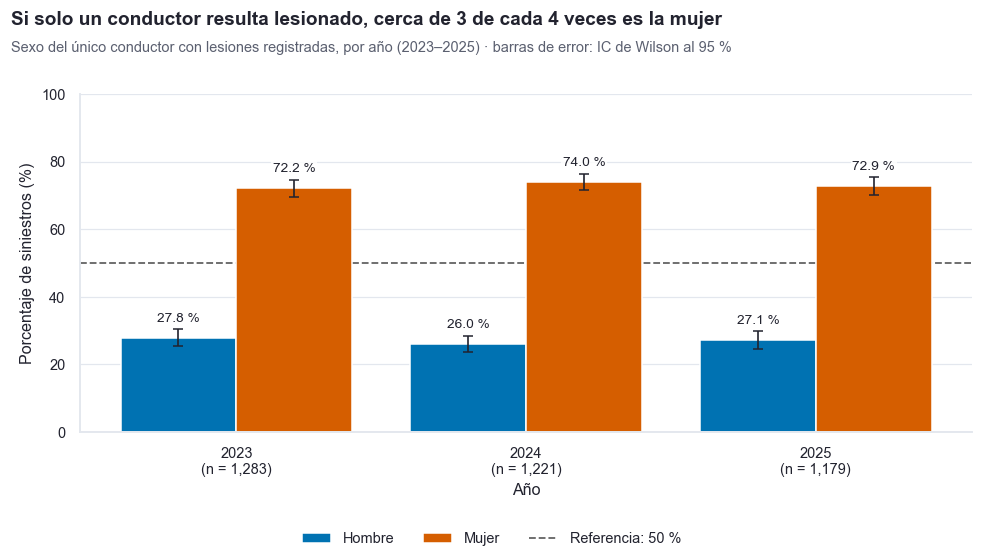

In [30]:
def graficar_un_lesionado(conteos):
    años = list(conteos)
    k_hombre = [conteos[a]["Hombre"] for a in años]
    k_mujer = [conteos[a]["Mujer"] for a in años]
    n = np.add(k_hombre, k_mujer)

    fig, ax = plt.subplots(figsize=TAMAÑO_FIGURA)
    barras_por_sexo(ax, [f"{a}\n(n = {t:,})" for a, t in zip(años, n)], k_hombre, k_mujer, n)
    ax.set(xlabel="Año", ylabel="Porcentaje de siniestros (%)")
    leyenda_abajo(fig, ax)
    titular(fig, "Si solo un conductor resulta lesionado, cerca de 3 de cada 4 veces es la mujer",
            "Sexo del único conductor con lesiones registradas, por año (2023–2025) · barras de error: IC de Wilson al 95 %")
    cerrar_figura(fig, "fig01_sexo_unico_lesionado")

graficar_un_lesionado(conteos_un_lesionado)


**Figura 1.** Porcentaje de siniestros con exactamente un conductor lesionado, según el sexo de ese conductor, por año. Bajo cada año se indica el número de siniestros (n); las barras de error son el intervalo de confianza de Wilson al 95 % y la línea punteada marca el 50 %. Población: siniestros de dos automóviles con un hombre y una mujer al volante e impacto frontal en ambos. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 4.2.2. Interpretación de resultados ####

Cuando solo uno de los conductores tiene lesiones registradas, se trata de la conductora en aproximadamente el 72% de los casos, durante los tres años de interés. Más específicamente:

- En 2023, la conductora fue la única con lesiones registradas en el 72.17% de los casos.

- En 2024, la conductora fue la única con lesiones registradas en el 74.04% de los casos.

- En 2025, la conductora fue la única con lesiones registradas en el 72.86% de los casos.


### 4.3. Siniestros con ambos conductores lesionados ###

En esta sección responderemos nuestra segunda conductora:

*¿Si ambos conductores presentan lesiones registradas de distinta gravedad, ¿hay una tendencia sobre quién presenta las más graves?*

#### 4.3.1. Cálculo de frecuencias relativas y absolutas ####

Para responder nuestra segunda pregunta conductora, seleccionaremos los siniestros en los que ambos conductores tienen lesiones registradas y compararemos sus categorías de gravedad. 

En un principio, distinguiremos tres casos: aquellos donde el hombre tiene lesiones más graves, aquellos donde la mujer tiene lesiones más graves y aquellos donde ambos tienen registrada la misma categoría de gravedad.

In [31]:
resumen = []

for año in análisis:
    vehículos = análisis[año]["vehicles"]
    def más_grave(collision_index: str) -> int:
        '''
        Recibe un identificador de siniestro y devuelve:

        1 si el hombre tiene lesiones más graves,

        2 si la mujer tiene lesiones más graves y

        0 si ambos tienen la misma gravedad.
        '''
        # Extraemos la pareja correspondiente con el identificador de siniestro (un DataFrame con dos filas)
        pareja = vehículos[vehículos["collision_index"] == collision_index]
        # Separamos los registros del conductor y de la conductora
        hombre = pareja[pareja["sex_of_driver"] == 1]
        mujer = pareja[pareja["sex_of_driver"] == 2]

        # Obtenemos las gravedades
        gravedad_hombre = hombre["casualty_severity"].iloc[0]
        gravedad_mujer = mujer["casualty_severity"].iloc[0]

        # ¡Ojo! La variable `casualty_severity` va de 1 a 3, donde 1 denota lesiones mortales, 2 denota lesiones graves y 3 denota lesiones leves
        # Es decir, números más bajos significan mayor gravedad
        if gravedad_hombre < gravedad_mujer:
            return 1
        elif gravedad_mujer < gravedad_hombre:
            return 2
        else:
            return 0

    # Seleccionamos los siniestros con ambos conductores lesionados.
    conductores_lesionados_por_siniestro = vehículos.groupby("collision_index")["casualty_severity"].count()
    siniestros_con_ambos_lesionados = conductores_lesionados_por_siniestro[conductores_lesionados_por_siniestro == 2
                                                                           ].index

    # Aplicamos la función a cada siniestro.
    resultados = pd.Series([más_grave(x) for x in siniestros_con_ambos_lesionados])

    # Contamos los resultados de las comparaciones.
    hombre = (resultados == 1).sum()
    mujer = (resultados == 2).sum()
    igual = (resultados == 0).sum()
    resumen.append({
        "Año": año,
        "Siniestros seleccionados (n)": len(análisis[año]["collisions"]),
        "Ambos lesionados (n)": len(siniestros_con_ambos_lesionados),
        "Distinta gravedad (n)": hombre + mujer,
        "Hombre más grave (n)": hombre,
        "Mujer más grave (n)": mujer,
        "Igual gravedad (n)": igual
    })

tabla_resumen = pd.DataFrame(resumen)
display(tabla_resumen)

Año,Siniestros seleccionados (n),Ambos lesionados (n),Distinta gravedad (n),Hombre más grave (n),Mujer más grave (n),Igual gravedad (n)
2023,2202,742,205,80,125,537
2024,2197,771,232,93,139,539
2025,2078,703,214,89,125,489


Observamos que el tamaño de muestra con este filtro (ambos conductores lesionados, con distinta gravedad) es considerablemente menor que en el análisis anterior,debido a que, en la mayoría de los siniestros con ambos conductores lesionados, ambos tienen registrada la misma categoría de gravedad. Estos casos se excluyen de la comparación de quién presenta las lesiones más graves.

#### 4.3.2. Visualización de resultados ####

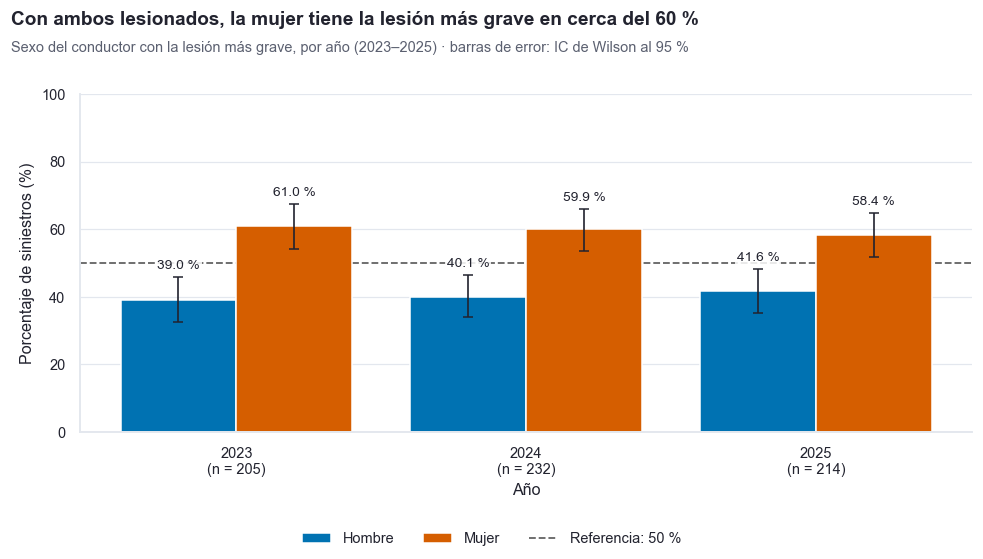

In [ ]:
def graficar_gravedad():
    t = tabla_resumen
    fig, ax = plt.subplots(figsize=TAMAÑO_FIGURA)
    barras_por_sexo(ax, [f"{a}\n(n = {n:,})" for a, n in zip(t["Año"], t["Distinta gravedad (n)"])],
                    t["Hombre más grave (n)"], t["Mujer más grave (n)"], t["Distinta gravedad (n)"])
    ax.set(xlabel="Año", ylabel="Porcentaje de siniestros (%)")
    leyenda_abajo(fig, ax)
    titular(fig, "Con ambos lesionados, la mujer tiene la lesión más grave en cerca del 60 %",
            "Sexo del conductor con la lesión más grave, por año (2023–2025) · barras de error: IC = 95 %")
    cerrar_figura(fig, "fig02_sexo_lesion_mas_grave")

graficar_gravedad()


**Figura 2.** Porcentaje de siniestros con ambos conductores lesionados y lesiones de distinta gravedad, según el sexo de quien tiene la lesión más grave, por año. Bajo cada año se indica el número de siniestros (n); las barras de error son el intervalo de confianza de Wilson al 95 % y la línea punteada marca el 50 %. Población: siniestros de dos automóviles con un hombre y una mujer al volante e impacto frontal en ambos. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 4.3.3. Interpretación de resultados ####

Cuando ambos conductores tienen lesiones registradas con distinto nivel de gravedad, las conductoras concentran alrededor del 60% de los casos de mayor gravedad. Más específicamente:

- En 2023, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 60.98% de los casos.

- En 2024, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 59.91% de los casos.

- En 2025, entre todos los siniestros donde ambos tuvieron lesiones registradas de distinta gravedad, la mujer tenía las lesiones registradas más graves en el 58.41% de los casos.

Los resultados son consistentes con las observaciones de la pregunta 1. A su vez, estos datos mantienen una estabilidad anual.

## 5. Extensión del análisis: relación entre la cilindrada y las lesiones registradas ##

En la sección 4 respondimos nuestras dos preguntas conductoras principales. Como complemento exploratorio—manteniendo estrictamente la **estructura emparejada** de nuestra población de estudio—, en esta sección incorporamos una variable numérica adicional disponible en `vehicles`: la **cilindrada del motor (`engine_capacity_cc`)** medida en centímetros cúbicos (cc).

En la sección 1.4.2 advertimos que STATS19 no registra la masa de los vehículos y que la categoría `vehicle_type == 9` agrupa desde autos subcompactos hasta camionetas SUV. Aunque la cilindrada del motor no equivale exactamente al peso del automóvil, suele asociarse con el tamaño y segmento de la unidad.

En particular, la tabla `vehicles` incluye la variable `engine_capacity_cc`, que registra la cilindrada de cada vehículo medida en centímetros cúbicos (cc). Si bien la cilindrada de un motor no equivale exactamente al peso del automóvil, suele asociarse con el tamaño y segmento de la unidad, por lo que será de nuestro interés investigar relaciones que emergen al considerar esta variable.

Cabe mencionar que, según lo declarado en la documentación oficial de STATS19, el código `-1` se utiliza para denotar valores faltantes o fuera de rango. 

### 5.1. Planteamiento del problema ###

En los siniestros de nuestra población donde ambos vehículos cuentan con una cilindrada válida registrada, podemos calcular la diferencia

$$ \Delta_{\text{cc}} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$$

donde $\text{cc}_{\text{hombre}}$ y $\text{cc}_{\text{mujer}}$ denotan las cilindradas de los vehículos conducidos por el hombre y por la mujer, respectivamente. Observamos que si ambas cilindradas coinciden, entonces la diferencia es cero, mientras que:

- La diferencia entre cilindradas $\Delta_{\text{cc}}$ es **positiva**, si el hombre conducía el vehículo con la mayor cilindrada.

- La diferencia entre cilindradas $\Delta_{\text{cc}}$ es **negativa**, si la mujer conducía el vehículo con la mayor cilindrada.

A partir de esto, formulamos las siguientes dos preguntas exploratorias complementarias:

*Primera pregunta.* Dentro de nuestra población emparejada, ¿cómo se distribuye la diferencia de cilindrada dentro de cada pareja según cuál de los dos conductores es el único con lesiones registradas?

*Segunda pregunta.* Si ponemos condiciones sobre la cilindrada, ¿hay cambios en el porcentaje de siniestros donde la mujer fue la única con lesiones registradas? Por ejemplo, si ponemos como condición que las cilindradas de los vehículos no difieran mucho entre sí, ¿se reduce el porcentaje de siniestros en los que la mujer fue la única con lesiones registradas?

#### 5.1.1. Consideraciones sobre automóviles eléctricos ####

Recordemos que la categoría `vehicle_type == 9` consiste en cualquier tipo de automóvil, lo cual puede incluir vehículos eléctricos. Como un automóvil eléctrico, por definición, no tiene cilindrada, es oportuno tomar esto en cuenta para el desarrollo de nuestro análisis complementario.

Afortunadamente, STATS19 registra el tipo de propulsión de un vehículo en la variable `propulsion_code` de la tabla `vehicles`. Según lo documentado en guía oficial de decodificación de variables de STATS19, los vehículos eléctricos reciben el código `3` en dicha variable, así que usaremos esta información para descartar los pares de automóviles en los que alguno de ellos está registrado como un vehículo eléctrico.

### 5.2. Incorporación de variables complementarias ###

Para responder las preguntas conductoras principales de nuestro proyecto, trabajamos con el diccionario `análisis` que incluía la información de la población de siniestros que estábamos considerando. 

El objetivo de esta sección es definir un nuevo diccionario, `análisis_cilindradas`, cuyos datos incluyan las variables `engine_capacity_cc`, para poder explorar nuestras preguntas complementarias, y `propulsion_code`, para eliminar los registros de siniestros en donde participó algún automóvil eléctrico:

In [33]:
variables_complementarias = ["propulsion_code", "engine_capacity_cc"]

In [34]:
análisis_cilindradas = {}

for año, datos_anuales in análisis.items():
    # Creamos un diccionario para el año correspondiente.
    análisis_cilindradas[año] = {}

    # Copiamos cada una de las tres tablas.
    for nombre, tabla in datos_anuales.items():
        análisis_cilindradas[año][nombre] = tabla.copy()

# Incorporamos las dos variables a la tabla de vehículos, para cada año
    análisis_cilindradas[año]["vehicles"] = análisis_cilindradas[año]["vehicles"].merge(
        datos[año]["vehicles"][
            ["collision_index", 
             "vehicle_reference"] + variables_complementarias],
        on=["collision_index", 
            "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

### 5.3. Calidad y limpieza de datos. ###

#### 5.3.1. Auditoría de calidad de `engine_capacity_cc` ####

Antes de calcular medidas de tendencia central o dispersión, verificamos que `engine_capacity_cc` esté presente en los tres años y auditamos posibles problemas de calidad: valores nulos estándar (`NaN`), código `-1` (dato faltante o fuera de rango), valores de `0` cc y posibles valores extremos (menores de 500 cc o mayores de 8,000 cc para un automóvil).

También comparamos las estadísticas descriptivas calculadas antes y después de excluir los valores no positivos.

In [35]:
auditoría_cc = []

for año in análisis_cilindradas:
    vehículos = análisis_cilindradas[año]["vehicles"]

    # Auditamos nulos, códigos especiales (-1 y 0) y posibles valores atípicos
    cc = vehículos["engine_capacity_cc"]
    n_total = len(cc)
    n_nan = int(cc.isna().sum())
    n_menos_uno = int((cc == -1).sum())
    n_otros_negativos = int((cc < -1).sum())
    n_cero = int((cc == 0).sum())
    n_bajo = int(((cc > 0) & (cc < 500)).sum())
    n_alto = int((cc > 8000).sum())

    # Comparamos la media antes y después de excluir valores no positivos
    cc_positivos = cc.where(cc > 0, np.nan)
    media_antes = round(cc.mean(), 2)
    media_después = round(cc_positivos.mean(), 2) if cc_positivos.notna().any() else np.nan
    desv_después = round(cc_positivos.std(), 2) if cc_positivos.notna().any() else np.nan
    auditoría_cc.append({
        "Año": año,
        "Vehículos (n)": n_total,
        "NaN estándar": n_nan,
        "Código -1 (n)": n_menos_uno,
        # "Código -1 (%)": round(100 * n_menos_uno / n_total, 2),
        "Valor 0 cc (n)": n_cero,
        "Otros negativos (n)": n_otros_negativos,
        "Cilindradas <500 cc": n_bajo,
        "Cilindradas >8000 cc": n_alto,
        "Media ANTES (con -1 y 0)": media_antes,
        "Media DESPUÉS (>0)": media_después,
        "Desv. Est. (>0)": desv_después
    })

tabla_auditoría_cc = pd.DataFrame(auditoría_cc)
display(tabla_auditoría_cc)

Año,Vehículos (n),NaN estándar,Código -1 (n),Valor 0 cc (n),Otros negativos (n),Cilindradas <500 cc,Cilindradas >8000 cc,Media ANTES (con -1 y 0),Media DESPUÉS (>0),Desv. Est. (>0)
2023,4404,0,377,0,0,1,0,1479.53,1618.14,514.12
2024,4394,0,659,0,0,2,0,1337.12,1573.21,469.43
2025,4156,0,388,0,0,0,0,1445.64,1594.6,488.58


#### 5.3.2. Auditoría de cilindrada en automóviles eléctricos ####

El objetivo de esta sección es detectar posibles inconsistencias entre ambas variables, es decir, examinaremos qué valores de `engine_capacity_cc` aparecen en los vehículos identificados mediante `propulsion_code == 3` (eléctricos).

In [36]:
auditoría_eléctricos = []

for año in análisis_cilindradas:
    vehículos = análisis_cilindradas[año]["vehicles"]

    # Seleccionamos los vehículos eléctricos.
    eléctricos = vehículos[vehículos["propulsion_code"] == 3]

    # Auditamos sus valores de cilindrada.
    cc = eléctricos["engine_capacity_cc"]
    n_total = len(cc)
    n_nan = int(cc.isna().sum())
    n_menos_uno = int((cc == -1).sum())
    n_cero = int((cc == 0).sum())
    n_positivos = int((cc > 0).sum())
    n_otros_negativos = int((cc < -1).sum())
    auditoría_eléctricos.append({
        "Año": año,
        "Eléctricos (n)": n_total,
        "NaN (n)": n_nan,
        "Código -1 (n)": n_menos_uno,
        "Valor 0 cc (n)": n_cero,
        "Cilindrada positiva (n)": n_positivos,
        "Otros negativos (n)": n_otros_negativos
    })

tabla_auditoría_eléctricos = pd.DataFrame(auditoría_eléctricos)
display(tabla_auditoría_eléctricos)

Año,Eléctricos (n),NaN (n),Código -1 (n),Valor 0 cc (n),Cilindrada positiva (n),Otros negativos (n)
2023,73,0,73,0,0,0
2024,108,0,107,0,1,0
2025,171,0,166,0,5,0


#### 5.3.3. Exclusión de siniestros con automóviles eléctricos

El siguiente código crea el diccionario `análisis_sin_eléctricos`, a partir de `análisis_cilindradas`, excluyendo las parejas completas de los siniestros en los que participó algún automóvil registrado como eléctrico. De esta manera, conservamos intactos los datos utilizados en las auditorías anteriores.

In [37]:
resumen = {}
análisis_sin_eléctricos = {}

for año in análisis_cilindradas:
    vehículos = análisis_cilindradas[año]["vehicles"]

    # Identificamos los siniestros con vehículos eléctricos
    eléctricos = vehículos.loc[vehículos["propulsion_code"] == 3]
    siniestros_a_descartar = eléctricos.groupby("collision_index").size()

    # Contamos las parejas descartadas
    resumen[año] = len(siniestros_a_descartar)
    análisis_sin_eléctricos[año] = {}

    # Descartamos las parejas completas de las tres tablas
    for nombre in análisis_cilindradas[año]:
        tabla = análisis_cilindradas[año][nombre]
        análisis_sin_eléctricos[año][nombre] = tabla.loc[
            tabla["collision_index"].isin(siniestros_a_descartar.index) == False
        ].copy()

display(pd.DataFrame.from_dict(
    resumen,
    orient="index",
    columns=["Parejas descartadas"]
))

,Parejas descartadas
2023,73
2024,104
2025,168


#### 5.3.4. Limpieza de cilindradas y verificación de la población resultante ####

**Problema.** En `engine_capacity_cc`, algunos datos faltantes o fuera de rango aparecen codificados con `-1` (lo cual sesga hacia abajo cualquier promedio y distorsiona la desviación estándar si se trata como una cilindrada real). Asimismo, pueden presentarse valores de `0` cc y valores extremos que requieren revisión. Además, para respetar la estructura por pares de nuestro estudio, no conviene promediar hombres y mujeres en dos conjuntos separados, sino comparar ambos automóviles *dentro del mismo siniestro*.

**Cómo lo abordamos (criterio estadístico).**

1. **Recodificación sin imputación.** Después de excluir los siniestros con automóviles eléctricos, consideramos válidas únicamente las cilindradas comprendidas entre 500 y 8,000 cc, reemplazando los valores fuera de este intervalo por `np.nan`. 

   Adoptamos este intervalo como un criterio operativo de limpieza para reducir la presencia de posibles errores de registro. Decidimos **no imputar** los faltantes porque asignar una cilindrada promedio artificial distorsionaría la diferencia real dentro de cada pareja.

2. **Transformación a tabla por pares (1 fila = 1 siniestro).** Reorganizamos los datos para que cada fila represente un siniestro completo con las columnas `cc_hombre`, `cc_mujer`, el desenlace de lesiones y la **diferencia emparejada** $\Delta_{\text{cc}} = \text{cc}_{\text{hombre}} - \text{cc}_{\text{mujer}}$ (valores positivos indican que el hombre conducía el automóvil de mayor cilindrada; valores negativos, que la mujer conducía el automóvil de mayor cilindrada).

**Consecuencias para nuestros datos y resultados.** Únicamente los siniestros donde **ambos** automóviles cuentan con cilindrada válida entran en el cálculo de $\Delta_{\text{cc}}$ (sin afectar los conteos ni los resultados de la sección 4). 

A continuación documentamos cuántos pares válidos se conservan por año, calculamos las medidas de tendencia central, dispersión (desviación estándar) y posición ($Q_1$, mediana, $Q_3$ e $IQR$), y estratificamos los siniestros con un solo conductor con lesiones registradas según quién conducía el automóvil de mayor cilindrada.

In [38]:
pares_lista = []
disponibilidad_pares = []

for año in análisis_sin_eléctricos:
    df = análisis_sin_eléctricos[año]["vehicles"].copy()

    # Reemplazamos las cilindradas fuera del intervalo válido por NaN
    df["cc_limpia"] = df["engine_capacity_cc"].where(
    df["engine_capacity_cc"].between(500, 8000), np.nan
)

    # Separamos los registros del conductor (hombre) y de la conductora (mujer)
    hombres = df[df["sex_of_driver"] == 1][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_hombre",
        "lesión_registrada": "lesión_hombre",
        "casualty_severity": "gravedad_hombre"
    })
    mujeres = df[df["sex_of_driver"] == 2][
        ["collision_index", "cc_limpia", "lesión_registrada", "casualty_severity"]
    ].rename(columns={
        "cc_limpia": "cc_mujer",
        "lesión_registrada": "lesión_mujer",
        "casualty_severity": "gravedad_mujer"
    })

    # Unimos ambos conductores del mismo siniestro en una sola fila (1 fila = 1 par)
    pares = hombres.merge(
        mujeres,
        on="collision_index",
        how="inner",
        validate="one_to_one"
    )
    pares["Año"] = año

    # Clasificamos el desenlace de lesiones de cada siniestro emparejado
    condiciones = [
        (pares["lesión_hombre"]) & (~pares["lesión_mujer"]),
        (~pares["lesión_hombre"]) & (pares["lesión_mujer"]),
        (pares["lesión_hombre"]) & (pares["lesión_mujer"])
    ]
    etiquetas = [
        "Solo hombre lesionado",
        "Solo mujer lesionada",
        "Ambos lesionados"
    ]
    pares["desenlace"] = np.select(
        condiciones,
        etiquetas,
        default="Ningún conductor lesionado"
    )

    # Calculamos la diferencia de cilindrada dentro de cada pareja (hombre menos mujer)
    pares["dif_cc"] = pares["cc_hombre"] - pares["cc_mujer"]

    # Registramos la disponibilidad anual de pares con ambas cilindradas válidas
    n_pares = len(pares)
    n_válidos = int(pares["dif_cc"].notna().sum())
    disponibilidad_pares.append({
        "Año": año,
        "Siniestros emparejados (n)": n_pares,
        "Pares con ambas cilindradas válidas (n)": n_válidos,
        "% disponible": round(100 * n_válidos / n_pares, 2)
    })
    pares_lista.append(pares)

# Consolidamos todos los pares del periodo y conservamos los que tienen ambas cilindradas válidas
pares_cc_todos = pd.concat(pares_lista, ignore_index=True)
pares_cc_válidos = pares_cc_todos[
    pares_cc_todos["dif_cc"].notna()
].copy()

# Detectamos automáticamente qué años aportaron pares válidos para etiquetar tablas y gráficas
años_con_datos = sorted(pares_cc_válidos["Año"].unique().tolist())
etiqueta_años = (
    f"{años_con_datos[0]}–{años_con_datos[-1]}"
    if len(años_con_datos) > 1
    else f"{años_con_datos[0]}"
)
print("Disponibilidad de pares con cilindrada válida en ambos automóviles:")
tabla_disponibilidad = pd.DataFrame(disponibilidad_pares)
display(tabla_disponibilidad)

Disponibilidad de pares con cilindrada válida en ambos automóviles:


Año,Siniestros emparejados (n),Pares con ambas cilindradas válidas (n),% disponible
2023,2129,1852,86.99
2024,2093,1626,77.69
2025,1910,1709,89.48


**Calidad y muestra.** Excluir los valores no positivos de `engine_capacity_cc` (el código `-1` estaba presente en entre el 8.6 % y el 15.0 % de los vehículos por año) produjo diferencias de hasta 236 cc en las medias anuales calculadas. Después de aplicar los criterios de limpieza y exclusión de automóviles eléctricos, se analizaron **5,187 pares** con cilindrada válida en ambos automóviles (80.08 % de la población emparejada de 2023–2025). 

Esta reducción debe considerarse al interpretar los resultados, pues la disponibilidad de cilindradas válidas podría estar relacionada con características de los vehículos o de los siniestros. Por tanto, no podemos asegurar que los siniestros excluidos tengan las mismas características que los conservados.

Para interpretar visualmente los resultados de este análisis, construimos dos figuras:

1. *Diagrama de cajas con la media marcada.* Muestra la mediana, los cuartiles y la media de la diferencia emparejada $\Delta_{\text{cc}}$ según cuál de los dos conductores es el único con lesiones registradas (sección 5.4.2).

2. *Gráfico de barras agrupadas.* Muestra los porcentajes de siniestros en los que solo el conductor o solo la conductora tiene lesiones registradas, según la diferencia de cilindrada entre ambos automóviles (sección 5.5.2).

### 5.4. Distribución de las diferencias de cilindrada según el desenlace de lesiones

#### 5.4.1. Estadística descriptiva 

In [39]:
# Función auxiliar para calcular medidas de tendencia central, dispersión y posición
def resumir_variable(serie, nombre):
    return {
        "Grupo / Variable": nombre,
        "Pares (n)": int(serie.count()),
        "Media (cc)": round(serie.mean(), 2),
        "Desv. Estándar (cc)": round(serie.std(), 2),
        "Mediana (cc)": round(serie.median(), 2),
        "Q1 (cc)": round(serie.quantile(0.25), 2),
        "Q3 (cc)": round(serie.quantile(0.75), 2),
        "IQR (cc)": round(serie.quantile(0.75) - serie.quantile(0.25), 2),
    }

# Calculamos los estadísticos generales y los de la diferencia emparejada Δcc por desenlace
filas_estadísticos = [
    resumir_variable(pares_cc_válidos["cc_hombre"], "Cilindrada auto del hombre (global)"),
    resumir_variable(pares_cc_válidos["cc_mujer"], "Cilindrada auto de la mujer (global)"),
    resumir_variable(pares_cc_válidos["dif_cc"], "Diferencia Δcc = hombre − mujer (global)"),
]

for grupo in ["Solo hombre lesionado", "Solo mujer lesionada", "Ambos lesionados"]:
    sub = pares_cc_válidos.loc[pares_cc_válidos["desenlace"] == grupo, "dif_cc"]
    if len(sub) > 0:
        filas_estadísticos.append(resumir_variable(sub, f"Δcc | {grupo}"))

tabla_estadísticos_cc = pd.DataFrame(filas_estadísticos)
tabla_estadísticos_cc.to_csv("resultados/anexo_estadisticos_cilindrada.csv", index=False)
print(f"Medidas de tendencia central, dispersión y posición ({etiqueta_años}):")
display(tabla_estadísticos_cc)

Medidas de tendencia central, dispersión y posición (2023–2025):


Grupo / Variable,Pares (n),Media (cc),Desv. Estándar (cc),Mediana (cc),Q1 (cc),Q3 (cc),IQR (cc)
Cilindrada auto del hombre (global),5187,1692.01,540.39,1597,1360,1984,624
Cilindrada auto de la mujer (global),5187,1507.46,430.34,1461,1200,1600,400
Diferencia Δcc = hombre − mujer (global),5187,184.54,686.79,165,-201.5,571,772.5
Δcc | Solo hombre lesionado,791,1.79,702.02,0,-396,444,840
Δcc | Solo mujer lesionada,2115,292.55,676.02,236,-99,609,708
Δcc | Ambos lesionados,1803,146.64,672.7,100,-243,508,751


#### 5.4.2. Visualización ####

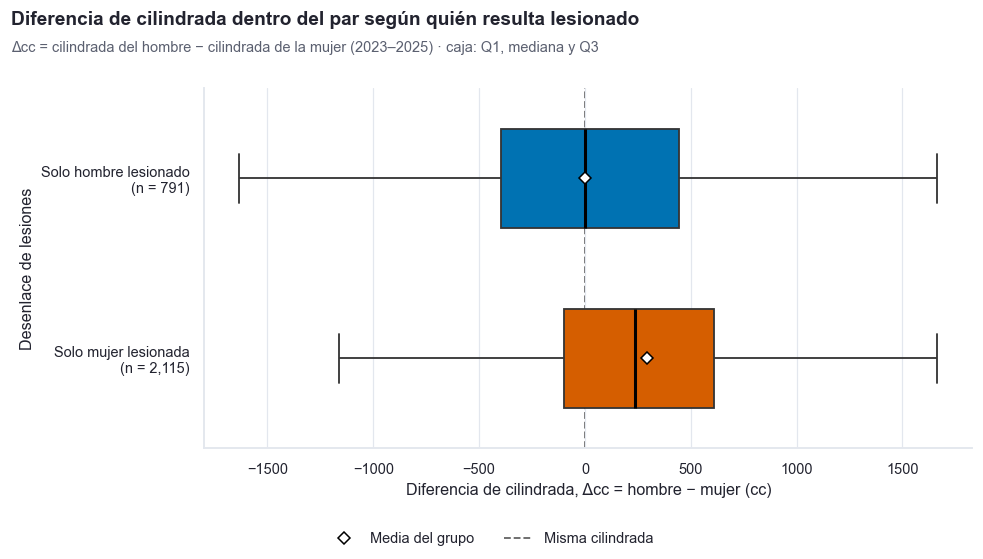

In [40]:
fig, ax = plt.subplots(figsize=TAMAÑO_FIGURA)

# Diagrama de cajas de la diferencia emparejada Δcc, con la media marcada
símbolo_media = caja_delta(ax, pares_cc_válidos, "dif_cc", ["Solo hombre lesionado", "Solo mujer lesionada"])
referencia(ax, valor=0, eje="x", etiqueta="Misma cilindrada")

ax.set(xlabel="Diferencia de cilindrada, Δcc = hombre − mujer (cc)", ylabel="Desenlace de lesiones")
leyenda_abajo(fig, ax, ncol=2, extra=[(símbolo_media, "Media del grupo")])
titular(fig, "Diferencia de cilindrada dentro del par según quién resulta lesionado",
        f"Δcc = cilindrada del hombre − cilindrada de la mujer ({etiqueta_años}) · caja: Q1, mediana y Q3")
cerrar_figura(fig, "fig03_delta_cilindrada_por_desenlace")


**Figura 3.** Distribución de la diferencia de cilindrada $\Delta_{\text{cc}}$ (hombre − mujer) en los siniestros con exactamente un conductor lesionado, según quién resultó lesionado. La caja va del primer al tercer cuartil con la mediana en negro, los bigotes llegan a 1.5 veces el rango intercuartílico, el rombo blanco es la media y no se muestran los valores atípicos. Solo pares con ambas cilindradas válidas. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 5.4.3. Interpretación de resultados ####


En el caso de siniestros en donde solo el conductor resultó lesionado, las diferencias de cilindradas presentan una media cercana a cero (1.79 cc) y una mediana de cero.

Por otro lado, en el caso de los siniestros en los que solo la conductora resultó lesionada, la distribución de las diferencias de cilindradas está ligeramente desplazada hacia la derecha; es decir, hacia valores positivos de $\Delta_{\text{cc}}$, que asociamos con cilindradas más grandes por parte del conductor.

### 5.5. Relación entre la diferencia de cilindradas y el sexo del único conductor lesionado ###

#### 5.5.1. Comparación de porcentajes según la diferencia de cilindradas

Para estudiar la relación entre las diferencias de cilindrada y las lesiones registradas, clasificaremos los siniestros en tres grupos: 

1. Aquellos donde el automóvil del hombre tiene una cilindrada superior en más de 100 cc.

2. Aquellos donde la diferencia absoluta de cilindradas es menor o igual a 100 cc.

3. Aquellos donde el automóvil de la mujer tiene una cilindrada superior en más de 100 cc.

Cabe mencionar que el umbral de 100 cc constituye un criterio exploratorio de agrupación y no garantiza condiciones físicas equivalentes entre los automóviles.

In [41]:
# En siniestros con exactamente un conductor lesionado, clasificamos quién tenía mayor cilindrada
pares_uno = pares_cc_válidos[
    pares_cc_válidos["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"])
].copy()
cond_ventaja = [
    pares_uno["dif_cc"] > 100,
    pares_uno["dif_cc"].abs() <= 100,
    pares_uno["dif_cc"] < -100
]
etiq_ventaja = [
    "Cilindrada del hombre > mujer (>100 cc)",
    "Cilindradas similares (|Δcc| ≤ 100 cc)",
    "Cilindrada de la mujer > hombre (>100 cc)"
]
pares_uno["ventaja_motor"] = np.select(cond_ventaja, etiq_ventaja, default="Otro")
filas_ventaja = []
for cat in etiq_ventaja:
    sub = pares_uno[pares_uno["ventaja_motor"] == cat]
    n_cat = len(sub)
    n_hom = int((sub["desenlace"] == "Solo hombre lesionado").sum())
    n_muj = int((sub["desenlace"] == "Solo mujer lesionada").sum())
    if n_cat > 0:
        filas_ventaja.append({
            "Comparación de motores dentro del par": cat,
            "Siniestros (n)": n_cat,
            "Solo hombre (n)": n_hom,
            "Solo mujer (n)": n_muj,
            "Solo hombre (%)": round(100 * n_hom / n_cat, 2),
            "Solo mujer (%)": round(100 * n_muj / n_cat, 2),
        })

tabla_ventaja_motor = pd.DataFrame(filas_ventaja)
tabla_ventaja_motor.to_csv("resultados/anexo_lesion_por_ventaja_motor.csv", index=False)
print(f"\nPorcentaje de lesión única según diferencia de cilindrada dentro del par ({etiqueta_años}):")
display(tabla_ventaja_motor)


Porcentaje de lesión única según diferencia de cilindrada dentro del par (2023–2025):


Comparación de motores dentro del par,Siniestros (n),Solo hombre (n),Solo mujer (n),Solo hombre (%),Solo mujer (%)
Cilindrada del hombre > mujer (>100 cc),1613,334,1279,20.71,79.29
Cilindradas similares (|Δcc| ≤ 100 cc),448,129,319,28.79,71.21
Cilindrada de la mujer > hombre (>100 cc),845,328,517,38.82,61.18


#### 5.5.2. Visualización de resultados

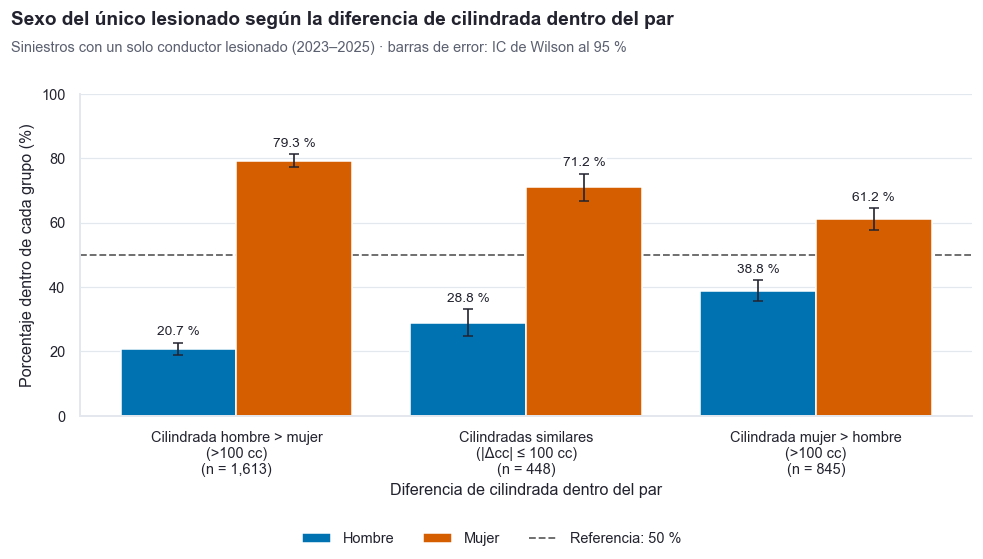

In [42]:
fig, ax = plt.subplots(figsize=TAMAÑO_FIGURA)
categoría = "Comparación de motores dentro del par"
etiquetas_cortas = []

for _, fila in tabla_ventaja_motor.iterrows():
    n = int(fila["Siniestros (n)"])
    if "hombre >" in fila[categoría]:
        etiquetas_cortas.append(f"Cilindrada hombre > mujer\n(>100 cc)\n(n = {n:,})")
    elif "similares" in fila[categoría]:
        etiquetas_cortas.append(f"Cilindradas similares\n(|Δcc| ≤ 100 cc)\n(n = {n:,})")
    else:
        etiquetas_cortas.append(f"Cilindrada mujer > hombre\n(>100 cc)\n(n = {n:,})")

barras_por_sexo(ax, etiquetas_cortas, tabla_ventaja_motor["Solo hombre (n)"],
                tabla_ventaja_motor["Solo mujer (n)"], tabla_ventaja_motor["Siniestros (n)"])
ax.set(xlabel="Diferencia de cilindrada dentro del par", ylabel="Porcentaje dentro de cada grupo (%)")
leyenda_abajo(fig, ax)
titular(fig, "Sexo del único lesionado según la diferencia de cilindrada dentro del par",
        f"Siniestros con un solo conductor lesionado ({etiqueta_años}) · barras de error: IC de Wilson al 95 %")
cerrar_figura(fig, "fig04_lesion_unica_por_diferencia_cilindrada")


**Figura 4.** Porcentaje de siniestros con un solo conductor lesionado, según su sexo, dentro de cada grupo de diferencia de cilindrada (umbral exploratorio de 100 cc). Bajo cada grupo se indica el número de siniestros (n); las barras de error son el intervalo de confianza de Wilson al 95 % y la línea punteada marca el 50 %. Solo pares con ambas cilindradas válidas. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 5.5.3. Interpretación de resultados

Para esta comparación consideramos únicamente los siniestros con ambas cilindradas válidas en los que exactamente uno de los dos conductores presentó lesiones registradas. Los porcentajes se calcularon dentro de cada grupo de diferencia de cilindrada, tomando como denominador el número de siniestros pertenecientes a ese grupo.

- En el primer grupo, el automóvil conducido por el hombre tiene una cilindrada superior a la del automóvil conducido por la mujer en más de 100 cc. 
   
    De los 1,613 siniestros que cumplen esta condición, en el 79.29 % únicamente la conductora presentó lesiones registradas, mientras que en el 20.71 % únicamente las presentó el conductor.

- En el segundo grupo, la diferencia absoluta entre las cilindradas de ambos automóviles es menor o igual a 100 cc. 
   
    De los 448 siniestros que cumplen esta condición, en el 71.21 % únicamente la conductora presentó lesiones registradas, mientras que en el 28.79 % únicamente las presentó el conductor.

- En el tercer grupo, el automóvil conducido por la mujer tiene una cilindrada superior a la del automóvil conducido por el hombre en más de 100 cc. 
   
    De los 845 siniestros que cumplen esta condición, en el 61.18% únicamente la conductora presentó lesiones registradas, mientras que en el 38.82 % únicamente las presentó el conductor.

El porcentaje de siniestros en los que únicamente la conductora presenta lesiones registradas disminuye **18.11 puntos porcentuales** entre los grupos extremos: pasa del 79.29% cuando el automóvil del hombre tiene una cilindrada superior en más de 100 cc al 61.18% cuando el automóvil de la mujer tiene una cilindrada superior en más de 100 cc. Sin embargo, incluso en este último grupo, las conductoras siguen concentrando la mayoría de los casos con lesiones registradas únicamente en uno de los dos conductores.

Estos resultados muestran una asociación entre la diferencia de cilindrada dentro de cada pareja y la distribución por sexo del único conductor con lesiones registradas, pero no permiten determinar qué parte de las diferencias observadas se explica por la cilindrada.


---

## 6. Extensión del análisis: diferencia de edad dentro de la pareja ##

En la sección 5 incorporamos una variable de los **vehículos** (la cilindrada). En esta sección incorporamos una variable de los **conductores**: su edad (`age_of_driver`, en `vehicles`). La razón es sencilla: las dos preguntas conductoras comparan a un hombre con una mujer, pero la edad es una característica previa al siniestro que podría estar ligada tanto a quién registra lesiones como a su gravedad.

### 6.1. Planteamiento del problema ###

Una forma tentadora de explorar la edad sería comparar la edad de *todos* los hombres contra la de *todas* las mujeres de nuestra población. Sin embargo, eso desecharía la estructura emparejada que hemos cuidado hasta ahora: aunque las edades medianas de hombres y mujeres resultaran parecidas, no sabríamos si **dentro de cada siniestro** el hombre suele ser mucho mayor o mucho menor que la mujer.

Por ello trabajamos, igual que con la cilindrada, con la diferencia dentro de cada pareja:

$$ \Delta_{\text{edad}} = \text{edad}_{\text{hombre}} - \text{edad}_{\text{mujer}} $$

Una diferencia **positiva** indica que el hombre es mayor que la mujer del mismo siniestro, y una **negativa**, que la mujer es mayor.

Clasificamos cada pareja en tres estratos según el valor de $\Delta_{\text{edad}}$. El corte de **10 años** es una convención que fijamos *antes* de ver los resultados (más adelante probaremos otros cortes para ver si las conclusiones dependen de él):

- **Mujer más de 10 años mayor:** $\Delta_{\text{edad}} < -10$.
- **Edades similares:** $|\Delta_{\text{edad}}| \leq 10$.
- **Hombre más de 10 años mayor:** $\Delta_{\text{edad}} > 10$.

Formulamos entonces dos preguntas exploratorias complementarias, una por cada pregunta conductora:

*Primera pregunta.* Dentro de cada estrato, ¿sigue siendo la conductora quien con más frecuencia es la única con lesiones registradas?

*Segunda pregunta.* Dentro de cada estrato, cuando ambos conductores tienen lesiones registradas de distinta gravedad, ¿sigue siendo la conductora quien tiene la más grave?

Antes de responderlas debemos incorporar la edad a nuestras tablas y revisar su calidad.

### 6.2. Incorporación de la edad y construcción de la tabla de parejas ###

Seguimos la misma técnica de la sección 5.2: copiamos la tabla `vehicles` de cada año de nuestra población y le agregamos `age_of_driver` con una unión izquierda. Nótese que partimos de `análisis` (todos los siniestros de nuestra población), y no de `análisis_sin_eléctricos`: la edad del conductor no depende del tipo de propulsión, así que no hay razón para excluir esos siniestros.

In [43]:
# Fijamos de antemano el corte de la diferencia de edad y las etiquetas de los tres estratos
UMBRAL_EDAD = 10
etiquetas_estrato = [
    "Mujer más de 10 años mayor",
    "Edades similares (|Δ| ≤ 10)",
    "Hombre más de 10 años mayor"
]

def asignar_estrato(dif_edad, umbral=UMBRAL_EDAD):
    '''
    Recibe una serie con la diferencia de edad (hombre − mujer) y devuelve
    el estrato de cada pareja como una variable categórica ordenada.
    Las diferencias faltantes (NaN) quedan sin estrato.
    '''
    estrato = np.select(
        [dif_edad < -umbral, dif_edad.abs() <= umbral, dif_edad > umbral],
        etiquetas_estrato,
        default=""
    )
    estrato = pd.Series(estrato, index=dif_edad.index).replace("", np.nan)
    return pd.Categorical(estrato, categories=etiquetas_estrato, ordered=True)

# Incorporamos `age_of_driver` a la tabla de vehículos de cada año
análisis_edad = {}

for año, datos_anuales in análisis.items():
    vehículos = datos_anuales["vehicles"].merge(
        datos[año]["vehicles"][["collision_index", "vehicle_reference", "age_of_driver"]],
        on=["collision_index", "vehicle_reference"],
        how="left",
        validate="one_to_one"
    )

    # Sanity check: la unión no debe agregar ni perder filas
    assert len(vehículos) == len(datos_anuales["vehicles"])
    análisis_edad[año] = vehículos

Ahora construimos, para cada año, una tabla con **una fila por pareja** (es decir, por siniestro), de modo análogo a como lo hicimos en la sección 5.3.4. Conservamos la edad *original* de cada conductor (con el código `-1`, si lo hay) para poder auditarla, y creamos una versión donde el código `-1` —que según la documentación de STATS19 denota un dato faltante o fuera de rango— se sustituye por `NaN`.

In [44]:
pares_lista_edad = []

for año, vehículos in análisis_edad.items():
    columnas = ["collision_index", "age_of_driver", "lesión_registrada", "casualty_severity"]

    # Separamos los registros del conductor (hombre) y de la conductora (mujer)
    hombres = vehículos[vehículos["sex_of_driver"] == 1][columnas].rename(columns={
        "age_of_driver": "edad_hombre_original",
        "lesión_registrada": "lesión_hombre",
        "casualty_severity": "gravedad_hombre"
    })
    mujeres = vehículos[vehículos["sex_of_driver"] == 2][columnas].rename(columns={
        "age_of_driver": "edad_mujer_original",
        "lesión_registrada": "lesión_mujer",
        "casualty_severity": "gravedad_mujer"
    })

    # Unimos ambos conductores del mismo siniestro (1 fila = 1 pareja)
    pares = hombres.merge(mujeres, on="collision_index", how="inner", validate="one_to_one")
    pares["Año"] = año

    # El código -1 denota dato faltante: lo convertimos en NaN (sin imputar)
    pares["edad_hombre"] = pares["edad_hombre_original"].where(pares["edad_hombre_original"] != -1, np.nan)
    pares["edad_mujer"] = pares["edad_mujer_original"].where(pares["edad_mujer_original"] != -1, np.nan)

    # Desenlace de lesiones (misma clasificación que en la sección 5.3.4)
    pares["desenlace"] = np.select(
        [
            (pares["lesión_hombre"]) & (~pares["lesión_mujer"]),
            (~pares["lesión_hombre"]) & (pares["lesión_mujer"]),
            (pares["lesión_hombre"]) & (pares["lesión_mujer"])
        ],
        ["Solo hombre lesionado", "Solo mujer lesionada", "Ambos lesionados"],
        default="Ningún conductor lesionado"
    )

    # Diferencia de edad dentro de la pareja (hombre menos mujer)
    pares["dif_edad"] = pares["edad_hombre"] - pares["edad_mujer"]
    pares_lista_edad.append(pares)

pares_edad_todos = pd.concat(pares_lista_edad, ignore_index=True)

# Sanity check: debemos recuperar exactamente los siniestros de nuestra población
assert len(pares_edad_todos) == sum(len(análisis[año]["collisions"]) for año in análisis)
print("Parejas (siniestros) de la población de estudio, por año:")
display(pares_edad_todos.groupby("Año").size().rename("Parejas (n)").to_frame())

Parejas (siniestros) de la población de estudio, por año:


,Parejas (n)
Año,
2023,2202
2024,2197
2025,2078


### 6.3. Calidad y limpieza de datos ###

#### 6.3.1. Auditoría de valores faltantes en `age_of_driver` ####

Antes de calcular cualquier diferencia, cuantificamos cuántos conductores tienen la edad registrada como faltante (`-1`) y cuántas parejas quedan con $\Delta_{\text{edad}}$ indefinida (basta con que falte la edad de *uno* de los dos conductores).

In [45]:
filas_auditoría = []

for año, g in pares_edad_todos.groupby("Año"):
    filas_auditoría.append({
        "Año": año,
        "Parejas (n)": len(g),
        "Sin edad del hombre (n)": int((g["edad_hombre_original"] == -1).sum()),
        "Sin edad de la mujer (n)": int((g["edad_mujer_original"] == -1).sum()),
        "Parejas sin Δedad (n)": int(g["dif_edad"].isna().sum()),
        "Parejas sin Δedad (%)": round(100 * g["dif_edad"].isna().mean(), 2)
    })

tabla_auditoría_edad = pd.DataFrame(filas_auditoría)

# Agregamos una fila con el total del periodo
total = {"Año": "Total"}
for columna in ["Parejas (n)", "Sin edad del hombre (n)", "Sin edad de la mujer (n)", "Parejas sin Δedad (n)"]:
    total[columna] = int(tabla_auditoría_edad[columna].sum())
total["Parejas sin Δedad (%)"] = round(100 * total["Parejas sin Δedad (n)"] / total["Parejas (n)"], 2)
tabla_auditoría_edad = pd.concat(
    [tabla_auditoría_edad, pd.DataFrame([total])],
    ignore_index=True
)
print("Valores faltantes en la edad del conductor:")
display(tabla_auditoría_edad)

Valores faltantes en la edad del conductor:


Año,Parejas (n),Sin edad del hombre (n),Sin edad de la mujer (n),Parejas sin Δedad (n),Parejas sin Δedad (%)
2023,2202,69,28,93,4.22
2024,2197,60,27,85,3.87
2025,2078,59,24,80,3.85
Total,6477,188,79,258,3.98


Para saber si estos faltantes son un asunto aleatorio o tienen relación con las lesiones, revisamos qué porcentaje de las parejas de cada desenlace no tiene $\Delta_{\text{edad}}$, y en qué situación de lesión se encuentran los conductores hombres sin edad.

In [46]:
# Porcentaje de parejas sin Δedad según el desenlace de lesiones
faltante_por_desenlace = (
    pares_edad_todos
    .groupby("desenlace")["dif_edad"]
    .agg(**{"Parejas (n)": "size", "Sin Δedad (n)": lambda s: int(s.isna().sum())})
)
faltante_por_desenlace["Sin Δedad (%)"] = (
    100 * faltante_por_desenlace["Sin Δedad (n)"] / faltante_por_desenlace["Parejas (n)"]
).round(2)
print("Parejas sin Δedad según el desenlace de lesiones:")
display(faltante_por_desenlace)

# Entre los hombres sin edad, ¿qué proporción no tiene lesión registrada?
sin_edad_h = pares_edad_todos[pares_edad_todos["edad_hombre_original"] == -1]
sin_edad_m = pares_edad_todos[pares_edad_todos["edad_mujer_original"] == -1]
print(f"Hombres sin edad registrada: {len(sin_edad_h)} "
      f"({100 * (~sin_edad_h['lesión_hombre']).mean():.1f} % sin lesión registrada)")
print(f"Mujeres sin edad registrada: {len(sin_edad_m)} "
      f"({100 * (~sin_edad_m['lesión_mujer']).mean():.1f} % sin lesión registrada)")

Parejas sin Δedad según el desenlace de lesiones:


,Parejas (n),Sin Δedad (n),Sin Δedad (%)
desenlace,,,
Ambos lesionados,2216,13,0.59
Ningún conductor lesionado,578,17,2.94
Solo hombre lesionado,994,49,4.93
Solo mujer lesionada,2689,179,6.66


Hombres sin edad registrada: 188 (94.1 % sin lesión registrada)
Mujeres sin edad registrada: 79 (65.8 % sin lesión registrada)


#### 6.3.2. Decisión de limpieza: análisis con parejas de edad válida ####

**Problema.** La edad de al menos uno de los dos conductores aparece como faltante (`-1`) en una pequeña proporción de las parejas (alrededor del 4 %), y el cálculo de $\Delta_{\text{edad}}$ exige las dos edades. Además, según la auditoría anterior, la edad falta sobre todo en conductores *sin lesión registrada*: el faltante no parece aleatorio.

**Cómo lo abordamos.** No imputamos las edades. Imputar la edad de un conductor a partir de la de su pareja (o de la mediana general) crearía un $\Delta_{\text{edad}}$ artificial justo en el estrato donde la información no existe, y la proporción de faltantes depende de las lesiones, que es precisamente lo que estudiamos. Por ello trabajamos únicamente con las parejas en las que ambas edades son válidas y reportamos cuántas se excluyen y cómo difieren de las incluidas.

**Consecuencias para nuestros datos o resultados.** Cuantificamos a continuación cuántas parejas dejamos fuera y si el porcentaje de la primera pregunta conductora (solo uno de los dos lesionado) cambia al restringirnos a las parejas con edad válida.

In [47]:
# Porcentaje de siniestros con un solo lesionado donde la lesionada es la mujer, según la pareja
# tenga o no ambas edades válidas
un_lesionado = pares_edad_todos[
    pares_edad_todos["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"])
]
grupos = {
    "Todas las parejas": un_lesionado,
    "Parejas con edad válida (se conservan)": un_lesionado[un_lesionado["dif_edad"].notna()],
    "Parejas sin Δedad (se excluyen)": un_lesionado[un_lesionado["dif_edad"].isna()],
}
filas = []
for nombre, g in grupos.items():
    filas.append({
        "Grupo (siniestros con un solo lesionado)": nombre,
        "Siniestros (n)": len(g),
        "Solo mujer lesionada (%)": round(100 * (g["desenlace"] == "Solo mujer lesionada").mean(), 2)
    })

tabla_consecuencia_edad = pd.DataFrame(filas)
display(tabla_consecuencia_edad)

# Parejas que perdemos en la segunda pregunta conductora (ambos lesionados con distinta gravedad)
dos_lesionados = pares_edad_todos[
    (pares_edad_todos["desenlace"] == "Ambos lesionados")
    & (pares_edad_todos["gravedad_hombre"] != pares_edad_todos["gravedad_mujer"])
]
print(f"Segunda pregunta: {len(dos_lesionados)} siniestros con ambos lesionados y distinta gravedad; "
      f"{int(dos_lesionados['dif_edad'].isna().sum())} sin Δedad.")

# A partir de aquí trabajamos solo con las parejas de edad válida
pares_edad = pares_edad_todos[pares_edad_todos["dif_edad"].notna()].copy()
pares_edad["estrato_edad"] = asignar_estrato(pares_edad["dif_edad"])
print(f"\nParejas conservadas para el análisis de edad: {len(pares_edad):,} "
      f"de {len(pares_edad_todos):,} ({100 * len(pares_edad) / len(pares_edad_todos):.2f} %)")

Grupo (siniestros con un solo lesionado),Siniestros (n),Solo mujer lesionada (%)
Todas las parejas,3683,73.01
Parejas con edad válida (se conservan),3455,72.65
Parejas sin Δedad (se excluyen),228,78.51


Segunda pregunta: 651 siniestros con ambos lesionados y distinta gravedad; 2 sin Δedad.

Parejas conservadas para el análisis de edad: 6,219 de 6,477 (96.02 %)


Con esta decisión conservamos **6,219 de las 6,477 parejas (96.02 %)** y excluimos 258 (3.98 %; 93, 85 y 80 en 2023, 2024 y 2025). En la primera pregunta conductora se pierden 228 de los 3,683 siniestros con un solo lesionado (6.19 %), y en la segunda solo 2 de 651.

El faltante, en efecto, no es aleatorio: el 94.1 % de los 188 hombres sin edad registrada no tiene lesión registrada, por lo que las parejas sin $\Delta_{\text{edad}}$ se concentran en el desenlace *solo la mujer lesionada* (6.66 % sin $\Delta_{\text{edad}}$, frente a 0.59 % cuando ambos están lesionados). Entre los siniestros excluidos, la mujer es la única lesionada en el 78.51 % de los casos (n = 228), contra 72.65 % entre los conservados. Aun así, el porcentaje global de la primera pregunta apenas cambia al restringirnos a las parejas con edad válida (de 73.01 % a 72.65 %, menos de medio punto porcentual).

En consecuencia, los resultados de esta sección describen únicamente a las parejas en las que ambas edades están registradas.

#### 6.3.3. Valores atípicos y consistencia entre tablas ####

Recordemos que un valor atípico no es necesariamente un error. Revisamos los extremos de la edad de los conductores y comprobamos, además, que la edad de `vehicles` sea coherente con la de `casualties` para los conductores lesionados (que aparecen en ambas tablas).

In [48]:
# Extremos de la edad válida de cada sexo
extremos = pd.DataFrame({
    "Hombres": pares_edad["edad_hombre"].describe(percentiles=[]).round(1),
    "Mujeres": pares_edad["edad_mujer"].describe(percentiles=[]).round(1),
})
display(extremos)
menores = {
    "Hombres de 16 años o menos": int((pares_edad["edad_hombre"] <= 16).sum()),
    "Mujeres de 16 años o menos": int((pares_edad["edad_mujer"] <= 16).sum()),
    "Hombres de 90 años o más": int((pares_edad["edad_hombre"] >= 90).sum()),
    "Mujeres de 90 años o más": int((pares_edad["edad_mujer"] >= 90).sum()),
}
print(menores)

# El conductor más joven de la población: ¿en qué estrato cae y cuánto influye?
fila_joven = pares_edad.loc[[pares_edad["edad_hombre"].idxmin()]]
print("\nParejas del conductor más joven:")
display(fila_joven[["Año", "edad_hombre", "edad_mujer", "dif_edad", "desenlace", "estrato_edad"]])

# Efecto de ese registro en el porcentaje de la primera pregunta de su estrato
estrato_joven = fila_joven["estrato_edad"].iloc[0]

for nombre, tabla in [("Con ese registro", pares_edad), ("Sin ese registro", pares_edad.drop(index=fila_joven.index))]:
    sub = tabla[
        (tabla["estrato_edad"] == estrato_joven)
        & (tabla["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"]))
    ]
    print(f"{nombre}: {100 * (sub['desenlace'] == 'Solo mujer lesionada').mean():.2f} % "
          f"de solo mujer lesionada (n = {len(sub):,})")

,Hombres,Mujeres
count,6219,6219
mean,43,43.5
std,18.6,17.5
min,4,16
50%,40,41
max,97,94


{'Hombres de 16 años o menos': 6, 'Mujeres de 16 años o menos': 1, 'Hombres de 90 años o más': 35, 'Mujeres de 90 años o más': 12}

Parejas del conductor más joven:


,Año,edad_hombre,edad_mujer,dif_edad,desenlace,estrato_edad
5887,2025,4,78,-74,Solo hombre lesionado,Mujer más de 10 años mayor


Con ese registro: 77.57 % de solo mujer lesionada (n = 1,226)
Sin ese registro: 77.63 % de solo mujer lesionada (n = 1,225)


In [49]:
# Consistencia de la edad entre `vehicles` y `casualties` para los conductores lesionados
filas_consistencia = []

for año in análisis:
    víctimas = datos[año]["casualties"]
    conductores = víctimas[víctimas["casualty_class"] == 1][
        ["collision_index", "vehicle_reference", "age_of_casualty"]
    ]
    vehículos = análisis_edad[año]
    vehículos = vehículos[vehículos["lesión_registrada"]][
        ["collision_index", "vehicle_reference", "age_of_driver"]
    ]
    unidos = vehículos.merge(conductores, on=["collision_index", "vehicle_reference"],
                             how="left", validate="one_to_one")

    # Comparamos solo cuando ambas edades son válidas
    ambas_válidas = unidos[(unidos["age_of_driver"] != -1) & (unidos["age_of_casualty"] != -1)]
    filas_consistencia.append({
        "Año": año,
        "Conductores lesionados (n)": len(unidos),
        "Con ambas edades válidas (n)": len(ambas_válidas),
        "Edades coincidentes (n)": int((ambas_válidas["age_of_driver"] == ambas_válidas["age_of_casualty"]).sum())
    })

tabla_consistencia = pd.DataFrame(filas_consistencia)
display(tabla_consistencia)

Año,Conductores lesionados (n),Con ambas edades válidas (n),Edades coincidentes (n)
2023,2767,2751,2751
2024,2763,2756,2756
2025,2585,2570,2570


**Valores atípicos.** Entre las parejas conservadas, la edad de los hombres va de 4 a 97 años y la de las mujeres de 16 a 94. Hay 6 hombres y 1 mujer de 16 años o menos, y 35 hombres y 12 mujeres de 90 años o más. Dado que un valor atípico no es necesariamente un error, **no eliminamos ninguno**: las edades extremas altas son posibles, y las bajas podrían corresponder a conductores muy jóvenes o a errores de captura que no podemos distinguir con los datos disponibles.

El caso más extremo es un conductor de 4 años (2025), una edad poco plausible para conducir. No tenemos forma de confirmar ni de corregir ese dato, así que lo conservamos, pero comprobamos que no condiciona los resultados: se trata de un único siniestro (de tipo *solo hombre lesionado*) dentro del estrato *mujer más de 10 años mayor*, y al retirarlo el porcentaje de la primera pregunta en ese estrato cambia de 77.57 % a 77.63 %.

**Consistencia entre tablas.** Para los conductores lesionados con ambas edades válidas (8,077), la edad registrada en `vehicles` coincide en todos los casos con la registrada en `casualties`. Los 38 conductores lesionados restantes no se pudieron comparar porque la edad es `-1` en alguna de las dos tablas.

### 6.4. Distribución de las diferencias de edad según el desenlace de lesiones ###

#### 6.4.1. Estadística descriptiva ####

Calculamos medidas de tendencia central, dispersión y posición de las edades y de $\Delta_{\text{edad}}$. Incluimos $|\Delta_{\text{edad}}|$ para medir qué tan distintas son las edades dentro de una pareja, sin importar quién es el mayor.

In [50]:
# Función auxiliar para calcular medidas de tendencia central, dispersión y posición
def resumir_edad(serie, nombre):
    return {
        "Grupo / Variable": nombre,
        "Parejas (n)": int(serie.count()),
        "Media (años)": round(serie.mean(), 2),
        "Desv. Estándar (años)": round(serie.std(), 2),
        "Mediana (años)": round(serie.median(), 2),
        "Q1 (años)": round(serie.quantile(0.25), 2),
        "Q3 (años)": round(serie.quantile(0.75), 2),
        "IQR (años)": round(serie.quantile(0.75) - serie.quantile(0.25), 2),
    }

filas_edad = [
    resumir_edad(pares_edad["edad_hombre"], "Edad del hombre (global)"),
    resumir_edad(pares_edad["edad_mujer"], "Edad de la mujer (global)"),
    resumir_edad(pares_edad["dif_edad"], "Δedad = hombre − mujer (global)"),
    resumir_edad(pares_edad["dif_edad"].abs(), "|Δedad| (global)"),
]
orden_desenlaces = [
    "Solo hombre lesionado",
    "Solo mujer lesionada",
    "Ambos lesionados",
    "Ningún conductor lesionado"
]

for grupo in orden_desenlaces:
    sub = pares_edad.loc[pares_edad["desenlace"] == grupo, "dif_edad"]
    filas_edad.append(resumir_edad(sub, f"Δedad | {grupo}"))

tabla_estadísticos_edad = pd.DataFrame(filas_edad)
tabla_estadísticos_edad.to_csv("resultados/tabla_edad_estadisticos.csv", index=False)
print("Medidas de tendencia central, dispersión y posición (2023–2025):")
display(tabla_estadísticos_edad)

# Correlación de Spearman entre las edades de los dos conductores de una misma pareja
spearman = pares_edad["edad_hombre"].corr(pares_edad["edad_mujer"], method="spearman")
print(f"\nCorrelación de Spearman entre la edad del hombre y la de la mujer de una misma pareja: {spearman:.3f}")

Medidas de tendencia central, dispersión y posición (2023–2025):


Grupo / Variable,Parejas (n),Media (años),Desv. Estándar (años),Mediana (años),Q1 (años),Q3 (años),IQR (años)
Edad del hombre (global),6219,43.02,18.56,40,27,56,29
Edad de la mujer (global),6219,43.48,17.46,41,29,56,27
Δedad = hombre − mujer (global),6219,-0.47,24.47,-1,-17,16,33
|Δedad| (global),6219,19.57,14.69,17,8,29,21
Δedad | Solo hombre lesionado,945,3.58,25.34,3,-13,21,34
Δedad | Solo mujer lesionada,2510,-2.62,24.19,-2,-19,14,33
Δedad | Ambos lesionados,2203,-0.73,24.04,0,-17,15,32
Δedad | Ningún conductor lesionado,561,3.39,24.67,2,-14,21,35



Correlación de Spearman entre la edad del hombre y la de la mujer de una misma pareja: 0.059


#### 6.4.2. Visualización ####

Para comparar la distribución de $\Delta_{\text{edad}}$ en los cuatro desenlaces posibles usamos un diagrama de cajas (con la media marcada), que muestra la mediana, los cuartiles y la dispersión sin ocultar que cada caja está formada por parejas distintas.

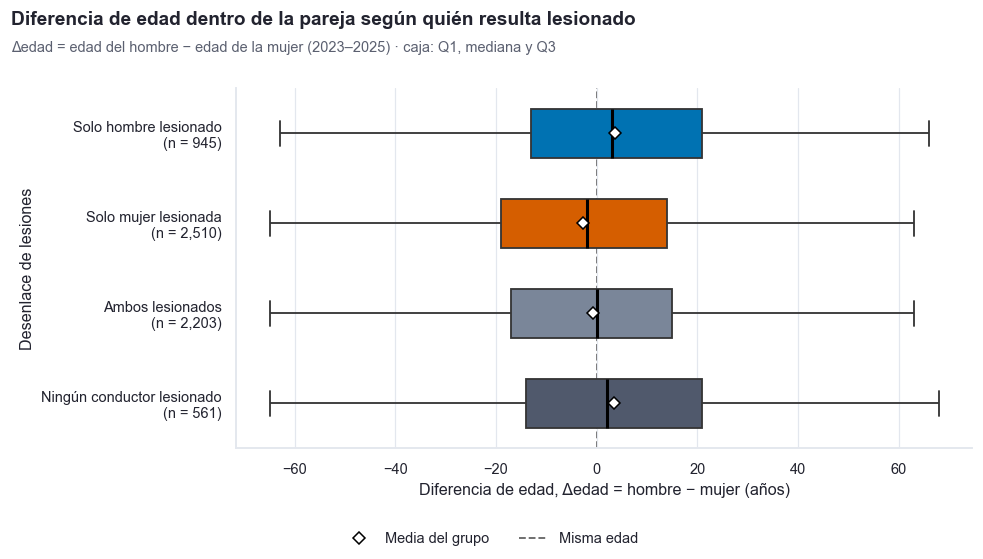

In [51]:
fig, ax = plt.subplots(figsize=TAMAÑO_FIGURA)

# Diagrama de cajas de la diferencia emparejada Δedad, con la media marcada
símbolo_media = caja_delta(ax, pares_edad, "dif_edad", orden_desenlaces)
referencia(ax, valor=0, eje="x", etiqueta="Misma edad")

ax.set(xlabel="Diferencia de edad, Δedad = hombre − mujer (años)", ylabel="Desenlace de lesiones")
leyenda_abajo(fig, ax, ncol=2, extra=[(símbolo_media, "Media del grupo")])
titular(fig, "Diferencia de edad dentro de la pareja según quién resulta lesionado",
        "Δedad = edad del hombre − edad de la mujer (2023–2025) · caja: Q1, mediana y Q3")
cerrar_figura(fig, "fig05_delta_edad_por_desenlace")


**Figura 5.** Distribución de la diferencia de edad $\Delta_{\text{edad}}$ (hombre − mujer) dentro de cada pareja, según el desenlace de lesiones. La caja va del primer al tercer cuartil con la mediana en negro, los bigotes llegan a 1.5 veces el rango intercuartílico, el rombo blanco es la media y no se muestran los valores atípicos. Solo parejas con ambas edades válidas. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 6.4.3. Interpretación de resultados ####

**Edades globales y edades dentro de la pareja.** En conjunto, hombres y mujeres tienen edades parecidas (medianas de 40 y 41 años). Sin embargo, esto no significa que las dos personas de una misma pareja tengan edades parecidas: la mediana de $|\Delta_{\text{edad}}|$ es de 17 años (Q1 = 8 y Q3 = 29), y $\Delta_{\text{edad}}$ tiene un rango intercuartílico de 33 años (de $-17$ a $+16$). Además, la correlación de Spearman entre las edades de los dos conductores de una pareja es de apenas 0.059, es decir, prácticamente no hay relación entre ellas. Medianas globales parecidas, por tanto, ocultan diferencias grandes dentro de cada pareja, que es justo lo que el diseño emparejado permite ver.

**Según el desenlace.** En los siniestros donde solo el conductor resultó lesionado, la mediana de $\Delta_{\text{edad}}$ es de $+3$ años (el hombre tiende a ser algo mayor que la mujer); donde solo la conductora resultó lesionada, es de $-2$ años (la mujer tiende a ser algo mayor), y cuando ambos tienen lesiones registradas es de 0. Estos desplazamientos son pequeños frente a la dispersión: el rango intercuartílico es de entre 32 y 35 años en los cuatro grupos y las cajas se traslapan casi por completo. Es decir, observamos una tendencia ligera, no una separación clara entre grupos.

**Limitaciones de la figura.** El diagrama de cajas resume la distribución pero no muestra cuántas parejas hay en cada valor, y los grupos tienen tamaños muy distintos (de 561 a 2,510 parejas). Tampoco dibujamos los valores atípicos, para no comprimir la escala; ya los revisamos en la sección 6.3.3.

### 6.5. Relación entre la diferencia de edad y las preguntas conductoras ###

#### 6.5.1. Cálculo de porcentajes por estrato ####

Repetimos las dos preguntas conductoras dentro de cada estrato de $\Delta_{\text{edad}}$, con las mismas definiciones de la sección 4:

- **Primera pregunta:** entre los siniestros con exactamente un conductor lesionado, el porcentaje en que la lesionada es la mujer.
- **Segunda pregunta:** entre los siniestros con ambos conductores lesionados y de distinta gravedad, el porcentaje en que la mujer tiene la lesión más grave (recordemos que un número menor en `casualty_severity` significa una lesión más grave).

Acompañamos cada porcentaje con un intervalo de confianza de Wilson al 95 %, que refleja la incertidumbre por el tamaño de muestra de cada estrato. Se trata de una medida descriptiva: no realizamos pruebas de hipótesis ni ajustamos por comparaciones múltiples.

In [52]:
def wilson(k, n, z=1.96):
    '''Intervalo de confianza de Wilson (95 %) para una proporción k/n.'''
    p = k / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return centro - mitad, centro + mitad

def calcular_por_estrato(pares, umbral=UMBRAL_EDAD):
    '''
    Para cada estrato de Δedad calcula, para las dos preguntas conductoras, el número de
    siniestros, el porcentaje en que la protagonista es la mujer y su intervalo de Wilson.
    '''
    pares = pares.copy()
    pares["estrato"] = asignar_estrato(pares["dif_edad"], umbral)
    filas = []
    for estrato, g in pares.groupby("estrato", observed=True):
        # Primera pregunta: exactamente un conductor lesionado
        p1 = g[g["desenlace"].isin(["Solo hombre lesionado", "Solo mujer lesionada"])]

        # Segunda pregunta: ambos lesionados y con distinta gravedad
        p2 = g[(g["desenlace"] == "Ambos lesionados") & (g["gravedad_hombre"] != g["gravedad_mujer"])]
        casos = [
            ("Primera", int((p1["desenlace"] == "Solo mujer lesionada").sum()), len(p1)),
            ("Segunda", int((p2["gravedad_mujer"] < p2["gravedad_hombre"]).sum()), len(p2)),
        ]
        for pregunta, k, n in casos:
            if n == 0:
                continue
            inferior, superior = wilson(k, n)
            filas.append({
                "Estrato": estrato,
                "Pregunta": pregunta,
                "Siniestros (n)": n,
                "Mujer (n)": k,
                "Mujer (%)": round(100 * k / n, 2),
                "IC95 inf (%)": round(100 * inferior, 2),
                "IC95 sup (%)": round(100 * superior, 2),
            })

    return pd.DataFrame(filas)

tabla_estratos = calcular_por_estrato(pares_edad)
tabla_estratos.to_csv("resultados/tabla_edad_p1_p2_por_estrato.csv", index=False)
print("Porcentaje de siniestros en que la mujer es la protagonista, por estrato de Δedad (2023–2025):")
display(tabla_estratos)

Porcentaje de siniestros en que la mujer es la protagonista, por estrato de Δedad (2023–2025):


Estrato,Pregunta,Siniestros (n),Mujer (n),Mujer (%),IC95 inf (%),IC95 sup (%)
Mujer más de 10 años mayor,Primera,1226,951,77.57,75.15,79.82
Mujer más de 10 años mayor,Segunda,231,156,67.53,61.25,73.24
Edades similares (|Δ| ≤ 10),Primera,1148,835,72.74,70.09,75.23
Edades similares (|Δ| ≤ 10),Segunda,216,135,62.5,55.88,68.68
Hombre más de 10 años mayor,Primera,1081,724,66.98,64.12,69.71
Hombre más de 10 años mayor,Segunda,202,96,47.52,40.75,54.39


#### 6.5.2. Visualización de resultados ####

En cada panel, la barra naranja es el porcentaje correspondiente a la mujer y la barra azul el del hombre (su complemento); ambas llevan el intervalo de Wilson al 95 %, que es simétrico entre las dos. La línea punteada marca el 50 %. Bajo cada estrato se indica el número de siniestros que sustenta el porcentaje.

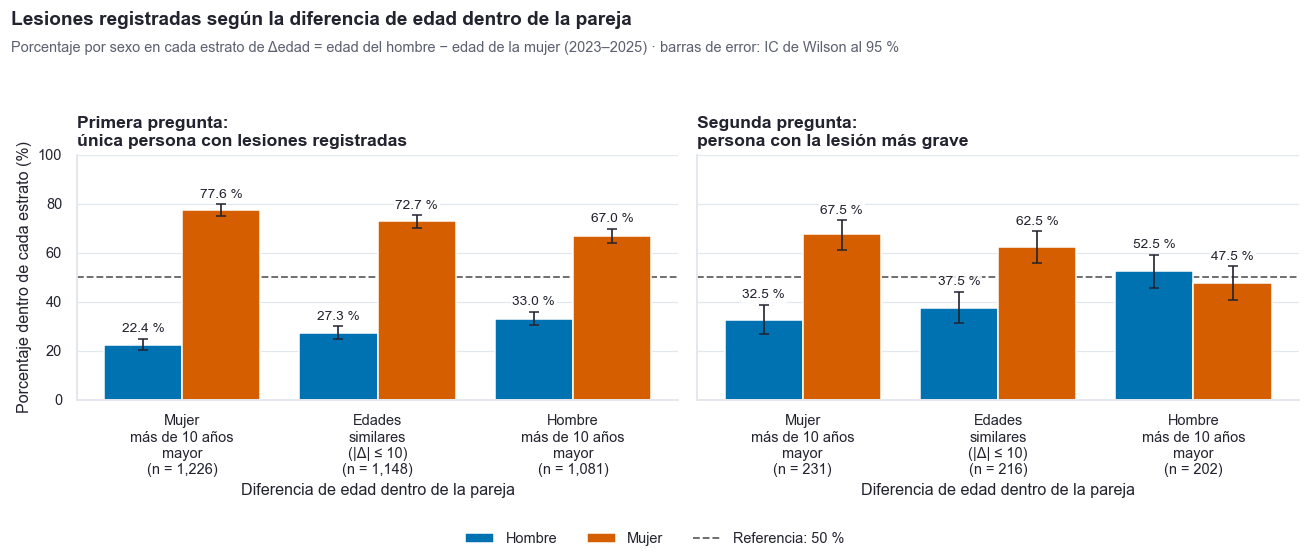

In [53]:
fig, ejes = plt.subplots(1, 2, figsize=TAMAÑO_FIGURA_DOBLE, sharey=True)
títulos = {
    "Primera": "Primera pregunta:\núnica persona con lesiones registradas",
    "Segunda": "Segunda pregunta:\npersona con la lesión más grave"
}
etiquetas_corta = ["Mujer\nmás de 10 años\nmayor", "Edades\nsimilares\n(|Δ| ≤ 10)", "Hombre\nmás de 10 años\nmayor"]

for ax, pregunta in zip(ejes, ["Primera", "Segunda"]):
    r = tabla_estratos[tabla_estratos["Pregunta"] == pregunta].set_index("Estrato").loc[etiquetas_estrato]
    etiquetas_x = [f"{e}\n(n = {n:,})" for e, n in zip(etiquetas_corta, r["Siniestros (n)"])]
    barras_por_sexo(ax, etiquetas_x, r["Siniestros (n)"] - r["Mujer (n)"], r["Mujer (n)"], r["Siniestros (n)"])
    ax.set(title=títulos[pregunta], xlabel="Diferencia de edad dentro de la pareja",
           ylabel="Porcentaje dentro de cada estrato (%)")

leyenda_abajo(fig, ejes[0], otros_ejes=[ejes[1]])
titular(fig, "Lesiones registradas según la diferencia de edad dentro de la pareja",
        "Porcentaje por sexo en cada estrato de Δedad = edad del hombre − edad de la mujer (2023–2025) · barras de error: IC de Wilson al 95 %")
cerrar_figura(fig, "fig06_p1_p2_por_estrato_edad", arriba=0.9)


**Figura 6.** Porcentaje de siniestros por sexo dentro de cada estrato de $\Delta_{\text{edad}}$ (corte de 10 años), para las dos preguntas conductoras. Bajo cada estrato se indica el número de siniestros (n); las barras de error son el intervalo de confianza de Wilson al 95 % y la línea punteada marca el 50 %. Solo parejas con ambas edades válidas. Fuente: STATS19, Department for Transport (Reino Unido), 2023–2025.

#### 6.5.3. Sensibilidad al corte y comportamiento por año ####

Como el corte de 10 años es una convención, repetimos el cálculo con cortes de 5 y 15 años. También desglosamos los resultados por año para ver si el patrón es estable; en la segunda pregunta los tamaños de muestra por año son pequeños, por lo que ese desglose es solo orientativo.

In [54]:
# Sensibilidad al corte de la diferencia de edad (solo se muestran los porcentajes de la mujer)
filas_sensibilidad = []

for umbral in [5, 10, 15]:
    t = calcular_por_estrato(pares_edad, umbral)
    for pregunta in ["Primera", "Segunda"]:
        s = t[t["Pregunta"] == pregunta].set_index("Estrato").loc[etiquetas_estrato]
        filas_sensibilidad.append({
            "Corte (años)": umbral,
            "Pregunta": pregunta,
            "Mujer más mayor (%)": s.iloc[0]["Mujer (%)"],
            "Edades similares (%)": s.iloc[1]["Mujer (%)"],
            "Hombre más mayor (%)": s.iloc[2]["Mujer (%)"],
        })

tabla_sensibilidad = pd.DataFrame(filas_sensibilidad)
print("Porcentaje de siniestros en que la mujer es la protagonista, según el corte de Δedad:")
display(tabla_sensibilidad)

# Desglose por año con el corte de 10 años
filas_año = []

for año, g in pares_edad.groupby("Año"):
    t = calcular_por_estrato(g)
    t.insert(0, "Año", año)
    filas_año.append(t)

tabla_por_año = pd.concat(filas_año, ignore_index=True)
print("\nDesglose por año (corte de 10 años):")
display(
    tabla_por_año.pivot_table(
        index=["Pregunta", "Estrato"], columns="Año", values=["Mujer (%)", "Siniestros (n)"], observed=True
    ).reindex(etiquetas_estrato, level="Estrato")
)

Porcentaje de siniestros en que la mujer es la protagonista, según el corte de Δedad:


Corte (años),Pregunta,Mujer más mayor (%),Edades similares (%),Hombre más mayor (%)
5,Primera,76.34,75,67.39
5,Segunda,64.87,66.1,50.79
10,Primera,77.57,72.74,66.98
10,Segunda,67.53,62.5,47.52
15,Primera,78.98,72.28,66.04
15,Segunda,66.32,61.59,47.77



Desglose por año (corte de 10 años):


Mujer (%)               Siniestros (n)  \
Año                                       2023   2024   2025           2023   
Pregunta Estrato                                                              
Primera  Mujer más de 10 años mayor      76.51  79.41  76.80          430.0   
         Edades similares (|Δ| ≤ 10)     72.62  76.37  69.33          409.0   
         Hombre más de 10 años mayor     65.00  65.32  70.77          360.0   
Segunda  Mujer más de 10 años mayor      65.06  72.00  65.75           83.0   
         Edades similares (|Δ| ≤ 10)     68.66  61.33  58.11           67.0   
         Hombre más de 10 años mayor     44.44  47.56  50.00           54.0   

                                                    
Año                                    2024   2025  
Pregunta Estrato                                    
Primera  Mujer más de 10 años mayor   408.0  388.0  
         Edades similares (|Δ| ≤ 10)  364.0  375.0  
         Hombre más de 10 años mayor  372.0  349.0  
Segunda  Mujer más de 10 años mayor    75.0   73.0  
         Edades similares (|Δ| ≤ 10)   75.0   74.0  
         Hombre más de 10 años mayor   82.0   66.0

#### 6.5.4. Interpretación y limitaciones ####

**Primera pregunta conductora.** Cuando exactamente uno de los dos conductores registra lesiones, la conductora sigue siendo la más frecuente en los tres estratos: 77.57 % cuando ella es más de 10 años mayor (n = 1,226; IC 75.15–79.82 %), 72.74 % cuando las edades son similares (n = 1,148) y 66.98 % cuando el hombre es más de 10 años mayor (n = 1,081; IC 64.12–69.71 %). Es decir, la diferencia de edad se asocia con el porcentaje, pero por sí sola no explica el patrón que observamos en la sección 4: incluso en el estrato más desfavorable para ella, las conductoras concentran dos de cada tres casos.

**Segunda pregunta conductora.** Cuando ambos conductores tienen lesiones registradas de distinta gravedad, la conductora tiene la lesión más grave en el 67.53 % de los casos si ella es más de 10 años mayor (n = 231; IC 61.25–73.24 %) y en el 62.50 % si las edades son similares (n = 216). En cambio, cuando el hombre es más de 10 años mayor el porcentaje es de 47.52 % (n = 202; IC 40.75–54.39 %): la conductora **deja de superar el 50 %**, y el intervalo de confianza incluye ese valor. Por año, en ese estrato el porcentaje fue de 44.44 %, 47.56 % y 50.00 % (n = 54, 82 y 66), un dato solo orientativo por el tamaño de muestra.

**Robustez.** Con cortes de 5 y de 15 años el orden de los estratos se mantiene: en la primera pregunta, la conductora es mayoría en todos los estratos y su porcentaje es menor cuando el hombre es el mayor (67.39 % con el corte de 5 años y 66.04 % con el de 15); en la segunda, el porcentaje de la conductora en ese mismo estrato es de 50.79 % y 47.77 %, respectivamente. El patrón por año de la primera pregunta es estable, con una excepción: en 2025 el porcentaje en el estrato de edades similares (69.33 %) es ligeramente menor que en el del hombre mayor (70.77 %), de modo que la tendencia no es estrictamente monótona en ese año.

**Limitaciones.**

- Se trata de un análisis descriptivo y asociativo. No realizamos pruebas de hipótesis ni ajustamos los intervalos por comparaciones múltiples, y los de la segunda pregunta (n entre 202 y 231) son amplios.
- La diferencia entre estratos **no demuestra** que la edad explique el patrón. La edad puede asociarse con características que no controlamos, como el tipo de automóvil, el tipo de trayecto o la fragilidad física, y STATS19 no registra estas últimas.
- La edad que analizamos es la del conductor. Aunque coincide con la edad registrada en `casualties` para los conductores lesionados, la edad no es el único factor que puede influir en la gravedad de las lesiones.
- Excluimos 258 parejas (3.98 %) sin edad válida en alguno de los conductores. Los faltantes se concentran en conductores sin lesión registrada, por lo que los resultados describen solo a las parejas con ambas edades registradas.
- El corte de 10 años es una convención. Los cortes alternativos que probamos no cambian las conclusiones cualitativas.

## 7. Conclusiones ##

### 7.1. Resultados principales

A partir del análisis descriptivo de los registros oficiales de STATS19 (para 2023, 2024 y 2025), enfocado en siniestros de exactamente dos automóviles, conducidos por un hombre y una mujer, en los que ambos vehículos registraron el frente como primer punto de impacto, se obtuvieron dos resultados principales, que posteriormente complementamos con dos análisis exploratorios (cilindrada y edad):

1. **Respecto a la primera pregunta conductora.**

   Cuando solo uno de los dos conductores registra lesiones, *más del 72% de los casos corresponden a la conductora* en los tres años analizados (72.17% en 2023, 74.04% en 2024 y 72.86% en 2025), frente a un porcentaje en conductores hombres de entre el 25.96% y el 27.83%.

2. **Respecto a la segunda pregunta conductora.**

   Cuando ambos conductores tienen lesiones registradas pero con distinta severidad, *alrededor del 60% de los casos de mayor gravedad corresponden a la conductora* (60.98% en 2023, 59.91% en 2024 y 58.41% en 2025).

3. **Respecto al análisis complementario de cilindradas.**

   Observamos diferencias en la proporción de siniestros donde la conductora fue la única de los dos conductores con lesiones registradas, según cuál de los dos automóviles tenía mayor cilindrada. Esta proporción fue del 79.29 % cuando el automóvil del hombre tenía una cilindrada superior en más de 100 cc y del 61.18 % cuando ocurría lo contrario. La diferencia entre ambos grupos fue de 18.11 puntos porcentuales.

4. **Respecto al análisis complementario de edad.**

   Al repetir las dos preguntas según la diferencia de edad dentro de cada pareja (6,219 parejas con ambas edades registradas, el 96 % de la población), la conductora siguió siendo mayoría entre los siniestros con un solo conductor lesionado en los tres estratos: entre 66.98 % y 77.57 %. Entre los siniestros con ambos conductores lesionados y distinta gravedad, la conductora tuvo la lesión más grave en el 67.53 % de los casos cuando ella era más de 10 años mayor, pero en el 47.52 % cuando el hombre era más de 10 años mayor (IC 40.75–54.39 %, n = 202), estrato en el que dejó de superar el 50 %.



### 7.2. Alcances y limitaciones


#### 7.2.1. Lo que permiten concluir los resultados ####

En los siniestros de nuestra población de estudio, encontramos diferencias marcadas y relativamente estables entre hombres y mujeres en dos desenlaces:
  
  - El sexo del único conductor con lesiones registradas (cuando exactamente uno de los dos tiene lesiones registradas).
  
  - El sexo del conductor con lesiones de mayor gravedad, cuando ambos tienen lesiones registradas y estas son de distinta gravedad.

En ambos análisis, las conductoras aparecen con mayor frecuencia que los conductores hombres en el desenlace estudiado.

Por otro lado, el análisis complementario de cilindradas muestra una asociación entre la diferencia de cilindrada de los automóviles dentro de cada pareja y el sexo del único conductor con lesiones registradas.

Finalmente, el análisis complementario de edad muestra que, dentro de cada pareja, la diferencia de edad entre los conductores se asocia con el porcentaje de siniestros en los que la conductora es la única con lesiones registradas y, de manera más marcada, con quién tiene la lesión más grave cuando ambos están lesionados.


#### 7.2.2. Lo que no permiten concluir los resultados ####

Nuestro análisis es de carácter exclusivamente exploratorio y **no pretende demostrar una relación causal** entre ninguna de las variables observadas.

En particular, nuestro análisis no permite establecer, por ejemplo, una relación causal  entre el sexo de un conductor y la propensión a presentar lesiones registradas (de mayor o menor gravedad) en un siniestro de dos automóviles.

De entrada, es importante recordar que en STATS19 solo se registran siniestros viales que:

1. Llegaron a conocimiento de las fuerzas policiales

2. Dejaron algún tipo de víctima.

3. Sucedieron en la vía pública.

De esta manera, los datos registrados en STATS19 **no representan** la totalidad de los siniestros de tránsito ocurridos en Gran Bretaña. 

Por otro lado, recordemos que según el Departamento de Transporte del Reino Unido existe un subregistro de víctimas de siniestros de tránsito en STATS19, especialmente en aquellos que involucran lesiones leves. Así pues, debemos tener presente que la ausencia de un conductor en `casualties` no garantiza que no haya sufrido lesiones en el siniestro correspondiente (una limitación que debe considerarse al interpretar los resultados de nuestras preguntas principales).

Otra dimensión a considerar es que, incluso en el universo de siniestros contemplados por STATS19, las tablas no recopilan todas las variables posibles que podrían explicar, total o parcialmente, la diferencia observada en nuestros resultados. Por ejemplo, STATS19 no proporciona información sobre la masa de los automóviles involucrados.

Lo anterior es particularmente importante para nuestras preguntas centrales, pues si existe una diferencia sistemática en el tamaño o masa promedio de los automóviles conducidos por mujeres y hombres, esto podría influir en los datos que analizamos en la sección 4 de este proyecto.

Finalmente, en cuanto al análisis con cilindradas, debemos tener en cuenta que la cilindrada es solo un indicador indirecto e imperfecto de características del automóvil, como su tamaño o masa, y presenta alta dispersión caso por caso. 

Por último, en el análisis de edad debemos recordar que los resultados describen únicamente a las parejas con ambas edades registradas (96 % de la población; los faltantes se concentran en conductores sin lesión registrada), que los estratos de la segunda pregunta tienen tamaños de muestra modestos y que la edad del conductor es solo una de las muchas características que podrían estar asociadas con las lesiones, por lo que no permite atribuirle ningún efecto causal.


### 7.3. Líneas futuras de análisis

En módulos posteriores del diplomado, este trabajo puede extenderse mediante pruebas de hipótesis formales para proporciones emparejadas (como la prueba de McNemar), modelos de regresión logística condicional por siniestro y el cruce con bases vehiculares externas que incorporen la masa y clasificación de seguridad de cada unidad.